In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event


# ----------------------------
# Config (EDIT THIS)
# ----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change this
POLICIES = ["aggressive", "idle", "dqn", "random"]#,"qrdqn"]
POWERS = [5, 10, 15, 20]

# Jam detection
JAM_THRESHOLD = 0.999   # you can tune; 0.995 or 0.99 might be better depending on your metric
TOLERANCE_STEPS = 5     # merge_asof tolerance

# ---------- schedule you described ----------
EP_DEC_STEPS = 1000
EP_SIM_STEPS = 10000
SIM_PER_DEC  = EP_SIM_STEPS // EP_DEC_STEPS  # 10

JAM_PERIOD_SIM = 2500
JAM_ON_SIM     = 1250

def infer_step_unit(max_step: int) -> str:
    """
    If max_step ~ 50k => likely decision steps (50 episodes * 1000)
    If max_step ~ 500k => likely sim steps (50 episodes * 10000)
    """
    if max_step <= 80_000:
        return "decision"
    if max_step <= 800_000:
        return "simulation"
    return "unknown"

def expected_jam_from_steps(steps: np.ndarray, step_unit: str) -> np.ndarray:
    """
    Build expected jam mask using your known on/off schedule.
    Assumes jammer schedule resets each episode.
    """
    if step_unit == "decision":
        step_in_ep_dec = steps % EP_DEC_STEPS
        step_in_ep_sim = step_in_ep_dec * SIM_PER_DEC
    elif step_unit == "simulation":
        step_in_ep_sim = steps % EP_SIM_STEPS
    else:
        # fallback: assume decision
        step_in_ep_dec = steps % EP_DEC_STEPS
        step_in_ep_sim = step_in_ep_dec * SIM_PER_DEC

    in_period = step_in_ep_sim % JAM_PERIOD_SIM
    return in_period < JAM_ON_SIM  # ON for first 1250 sim-steps of each 2500

def run_lengths(mask: np.ndarray) -> np.ndarray:
    """Lengths of contiguous True segments."""
    if len(mask) == 0:
        return np.array([], dtype=int)
    x = mask.astype(int)
    dx = np.diff(np.r_[0, x, 0])
    starts = np.where(dx == 1)[0]
    ends   = np.where(dx == -1)[0]
    return (ends - starts)

def debug_jam_detection(event_file: Path,
                        jam_threshold=0.999,
                        tol_steps=5,
                        plot_episode_idx=0):
    # read your scalars
    lat = read_scalar_from_event(event_file, "latency/urllc").sort_values("step")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio").sort_values("step")

    print("lat points:", len(lat), "prb points:", len(prb))
    if lat.empty or prb.empty:
        print("Missing tags; can't debug.")
        return

    # merge (same as your pipeline)
    df = merge_latency_prb(lat, prb)
    print("merged points:", len(df))
    if df.empty:
        print("Merge produced empty df. Increase tolerance or check step alignment.")
        return
    
    print(df["effective_prb_ratio"].describe())
    print("jam fraction:", df["jammed"].mean())   # should be ~0.5
    # if step is sim-step
    df["ep"] = (df["step"] // 10000).astype(int)
    print(df.groupby("ep")["jammed"].mean().head(10))  # each should be ~0.5



    max_step = int(df["step"].max())
    unit = infer_step_unit(max_step)
    print("max step:", max_step, "=> inferred unit:", unit)

    # your detected jam
    detected = df["effective_prb_ratio"].to_numpy() < jam_threshold

    # expected jam from schedule
    expected = expected_jam_from_steps(df["step"].to_numpy(), unit)

    # confusion
    TP = int(np.sum(detected & expected))
    FP = int(np.sum(detected & ~expected))
    FN = int(np.sum(~detected & expected))
    TN = int(np.sum(~detected & ~expected))

    print("\n--- Jam detection vs expected schedule ---")
    print("threshold:", jam_threshold)
    print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}")
    print("Detected jam fraction:", detected.mean())
    print("Expected  jam fraction:", expected.mean(), "(should be ~0.5)")

    # run-length sanity
    det_runs = run_lengths(detected)
    exp_runs = run_lengths(expected)
    print("\n--- Run lengths (contiguous ON segments) ---")
    if len(det_runs):
        print("Detected runs: count", len(det_runs),
              "mean", det_runs.mean(), "median", np.median(det_runs),
              "min", det_runs.min(), "max", det_runs.max())
    else:
        print("Detected runs: none")
    if len(exp_runs):
        print("Expected runs:  count", len(exp_runs),
              "mean", exp_runs.mean(), "median", np.median(exp_runs),
              "min", exp_runs.min(), "max", exp_runs.max())

    # episode-level check
    if unit == "decision":
        ep_idx = (df["step"] // EP_DEC_STEPS).astype(int)
        steps_in_ep = (df["step"] % EP_DEC_STEPS).astype(int)
    else:
        ep_idx = (df["step"] // EP_SIM_STEPS).astype(int)
        steps_in_ep = (df["step"] % EP_SIM_STEPS).astype(int)

    df2 = df.copy()
    df2["ep"] = ep_idx
    df2["detected"] = detected
    df2["expected"] = expected
    per_ep = df2.groupby("ep")[["detected","expected"]].mean()
    print("\n--- Per-episode jam fraction (first 10 eps) ---")
    print(per_ep.head(10))

    # plot one episode
    ep = plot_episode_idx
    one = df2[df2["ep"] == ep].copy()
    if one.empty:
        print(f"No data found for episode {ep} in merged df.")
        return

    plt.figure(figsize=(12,4))
    plt.plot(one["step"], one["effective_prb_ratio"], label="effective_prb_ratio")
    # mark expected vs detected
    ymin, ymax = one["effective_prb_ratio"].min(), one["effective_prb_ratio"].max()
    y0 = ymin - 0.02*(ymax-ymin if ymax>ymin else 1)

    plt.scatter(one.loc[one["expected"], "step"], np.full(one["expected"].sum(), y0),
                s=8, label="expected jam (schedule)")
    plt.scatter(one.loc[one["detected"], "step"], np.full(one["detected"].sum(), y0 - 0.01),
                s=8, label="detected jam (threshold)")

    plt.axhline(jam_threshold, linestyle="--", linewidth=1, label="threshold")
    plt.title(f"Episode {ep}: effective_ratio + expected/detected jam markers")
    plt.xlabel("TensorBoard step")
    plt.ylabel("effective_prb_ratio")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [10]:
def find_event_file(policy_dir: Path, test_dir_name: str) -> Path | None:
    """
    policy_dir/
      test_dir_name/
        run_dir/
          events.out.tfevents....
    Returns first (largest) event file found.
    """
    test_dir = policy_dir / test_dir_name
    if not test_dir.exists():
        return None

    run_dirs = [p for p in test_dir.iterdir() if p.is_dir()]
    if not run_dirs:
        return None

    # In your structure there is typically 1 run folder
    # but we search them all to be safe.
    candidates = []
    for rd in run_dirs:
        candidates.extend(list(rd.glob("events.out.tfevents.*")))

    if not candidates:
        return None

    # pick the biggest file (usually the full one)
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]



def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    """Return DataFrame(step, value) for a scalar tag from a tfevents file."""
    rows = []
    for raw in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(raw)
        if not ev.summary:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag == tag and v.HasField("simple_value"):
                rows.append({"step": step, "value": float(v.simple_value)})
    if not rows:
        return pd.DataFrame(columns=["step", "value"])
    return pd.DataFrame(rows).sort_values("step").reset_index(drop=True)



def merge_latency_prb(lat_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align latency and effective_ratio by nearest step."""
    lat_df = lat_df.rename(columns={"value": "latency_sec"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        lat_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["latency_ms"] = df["latency_sec"] * 1000.0  # seconds -> ms (correct if latency is in seconds)
    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_latency_during_jam(event_file: Path) -> float:
    """Compute mean URLLC latency (ms) during jammed samples."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan

    df = merge_latency_prb(lat, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    print("lent(jam(file)):", len(jam_df) )
    return float(jam_df["latency_ms"].mean())



def mean_latency_overall(event_file: Path) -> float:
    """Mean URLLC latency (ms) across all samples (jam + no-jam)."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    if df.empty:
        return np.nan
    return float(df["latency_ms"].mean())


def mean_latency_no_jam(event_file: Path) -> float:
    """Mean URLLC latency (ms) during non-jammed samples only."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    nojam_df = df[~df["jammed"]]
    if nojam_df.empty:
        return np.nan
    return float(nojam_df["latency_ms"].mean())

lat points: 49950 prb points: 49950
merged points: 49950
count    49950.000000
mean         0.987513
std          0.012500
min          0.975000
25%          0.975000
50%          1.000000
75%          1.000000
max          1.000000
Name: effective_prb_ratio, dtype: float64
jam fraction: 0.4994994994994995
ep
0    0.499499
1    0.499499
2    0.499499
3    0.499499
4    0.499499
5    0.499499
6    0.499499
7    0.499499
8    0.499499
9    0.499499
Name: jammed, dtype: float64
max step: 499990 => inferred unit: simulation

--- Jam detection vs expected schedule ---
threshold: 0.999
TP=24950  FP=0  FN=0  TN=25000
Detected jam fraction: 0.4994994994994995
Expected  jam fraction: 0.4994994994994995 (should be ~0.5)

--- Run lengths (contiguous ON segments) ---
Detected runs: count 200 mean 124.75 median 125.0 min 124 max 125
Expected runs:  count 200 mean 124.75 median 125.0 min 124 max 125

--- Per-episode jam fraction (first 10 eps) ---
    detected  expected
ep                    
0   0.

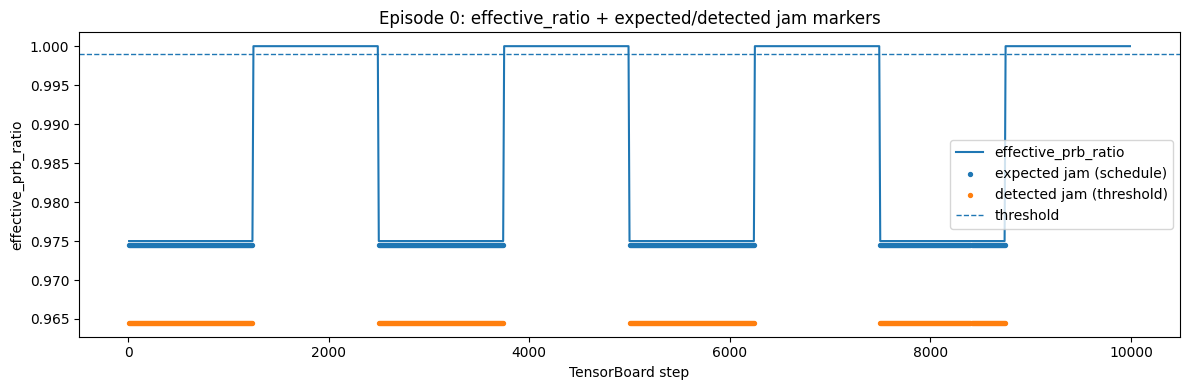

In [11]:
ev_file = find_event_file(ROOT/"dqn", "gym_from_testing_config_1ms_10s_8UE_jam_fixed_5")
debug_jam_detection(ev_file, jam_threshold=0.999, tol_steps=5, plot_episode_idx=0)

Runs found: 41


,run_dir,policy,pattern,power,overall_latency_ms
0,../../tb_logs/res_validator/idle__20260120_092...,idle,unknown,10,137.733307
1,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,fixed,5,93.504930
2,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,decreasing,20260119,126.706976
3,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,fixed,20260119,93.504930
4,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,fixed,15,132.181828
5,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,random,20260119,115.399374
6,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,fixed,20,137.742425
7,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,fixed,10,110.215595
8,../../tb_logs/res_validator/qrdqn/gym_from_tes...,dqn,increasing,20260119,129.869338
9,../../tb_logs/res_validator/random/gym_from_te...,random,fixed,5,59.124154


,pattern,policy,power,mean_latency_ms,std_latency_ms,n
0,decreasing,aggressive,20260118,147.552351,NaN,1
1,decreasing,dqn,20260117,117.129443,NaN,1
2,decreasing,dqn,20260119,126.706976,NaN,1
3,decreasing,idle,20260118,260.208524,NaN,1
4,decreasing,random,20260118,83.687211,NaN,1
5,fixed,aggressive,5,146.943985,NaN,1
6,fixed,aggressive,10,147.121448,NaN,1
7,fixed,aggressive,15,147.527818,NaN,1
8,fixed,aggressive,20,147.855425,NaN,1
9,fixed,aggressive,20260118,146.943985,NaN,1


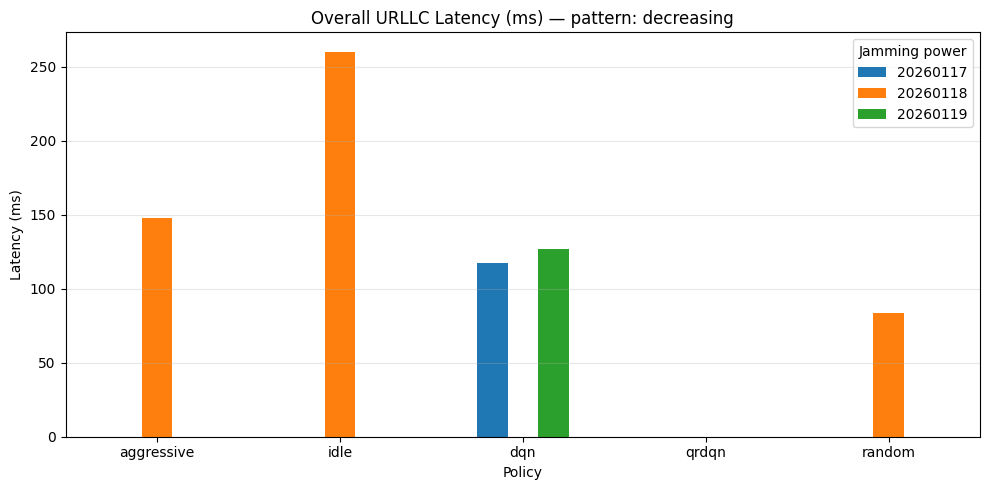

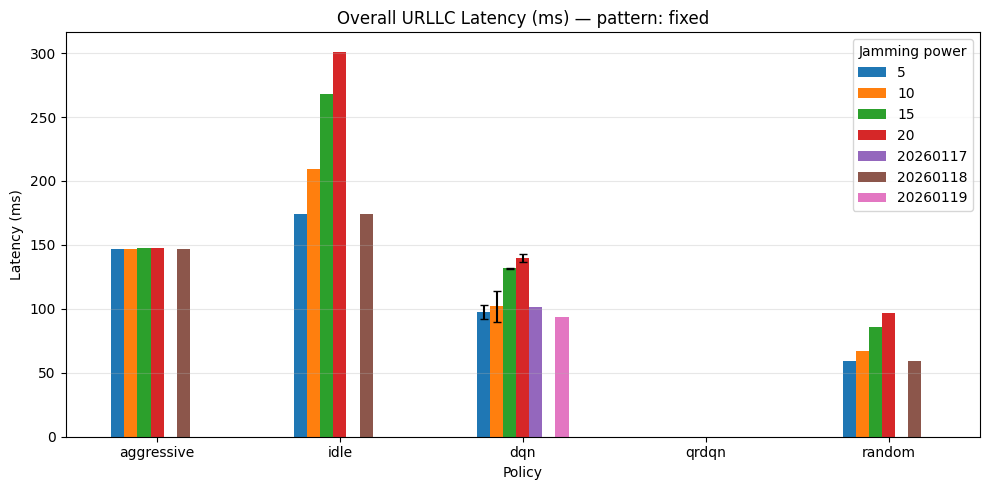

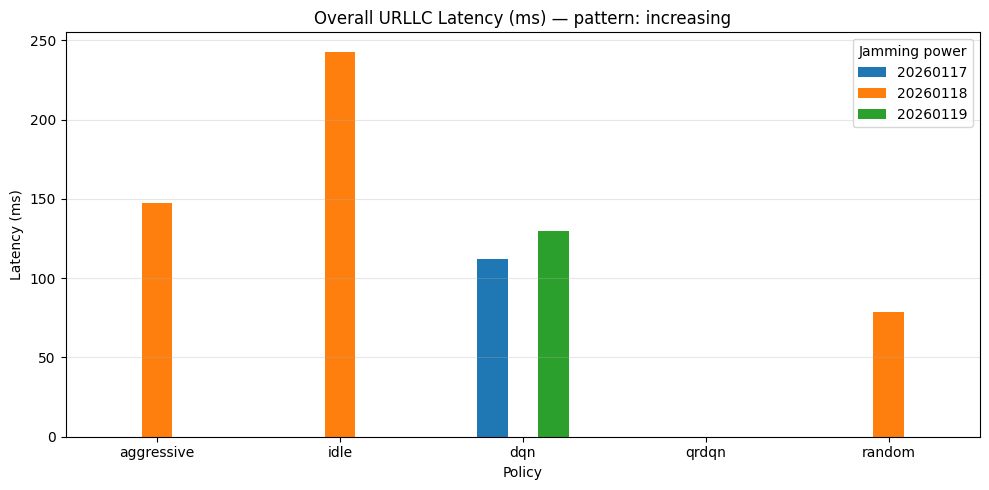

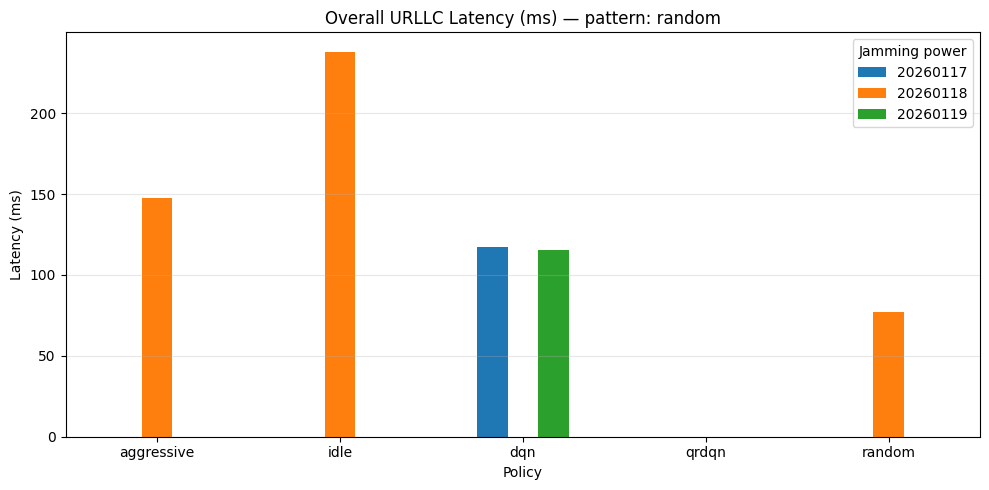

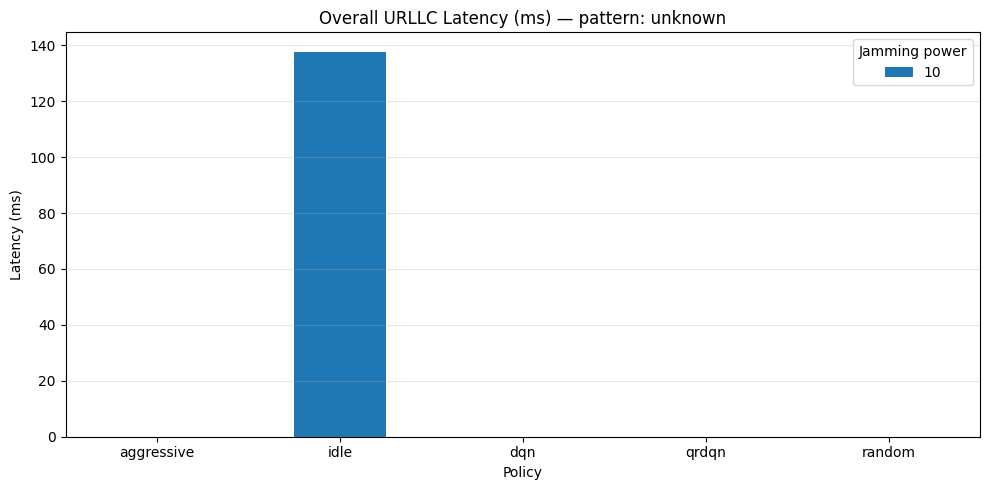

In [16]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# Config (EDIT THESE)
# ----------------------------
ROOT = Path("../../tb_logs/res_validator")   # <-- your TB root
POLICIES = ["aggressive", "idle", "dqn", "qrdqn", "random"]  # add "qrdqn" if needed
POWERS = [5, 10, 15, 20]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]  # if you have these in paths
LAT_TAG = "latency/urllc"   # <-- change if different
WARMUP_STEPS = 0            # set >0 if you want to ignore early steps
USE_MEDIAN = False          # if True, use median instead of mean for "overall latency"


# ----------------------------
# Helpers
# ----------------------------
def find_event_files(root: Path):
    return list(root.rglob("events.out.tfevents.*"))

def extract_meta_from_path(p: Path):
    s = str(p).lower()

    # policy
    policy = next((pol for pol in POLICIES if pol in s), None)

    # pattern
    pattern = next((pat for pat in PATTERNS if pat in s), None)

    # power (tries common patterns: power_10, power10, pwr10, jam_10, etc.)
    power = None
    m = re.search(r"(power|pwr|jam|jamming)[^0-9]*([0-9]+)", s)
    if m:
        power = int(m.group(2))
    else:
        # fallback: pick first POWERS value that appears as a whole number segment
        for pw in POWERS:
            if re.search(rf"(^|[^0-9]){pw}([^0-9]|$)", s):
                power = pw
                break

    return policy, pattern, power

def load_scalar_series(event_file: Path, tag: str):
    """
    Returns: (steps, values) for a scalar tag, or (None, None) if missing.
    """
    try:
        ea = EventAccumulator(
            str(event_file.parent),
            size_guidance={"scalars": 0, "histograms": 0, "images": 0, "tensors": 0}
        )
        ea.Reload()
        if tag not in ea.Tags().get("scalars", []):
            return None, None
        events = ea.Scalars(tag)
        steps = np.array([e.step for e in events], dtype=int)
        vals = np.array([e.value for e in events], dtype=float)
        return steps, vals
    except Exception:
        return None, None

def overall_latency_ms(steps, vals, warmup_steps=0, use_median=False):
    if steps is None or vals is None or len(vals) == 0:
        return np.nan
    mask = steps >= warmup_steps
    vals = vals[mask]
    if len(vals) == 0:
        return np.nan
    # seconds -> ms
    vals_ms = vals * 1000.0
    return float(np.nanmedian(vals_ms) if use_median else np.nanmean(vals_ms))


# ----------------------------
# Build table: one row per run
# ----------------------------
rows = []
event_files = find_event_files(ROOT)

for ev in event_files:
    policy, pattern, power = extract_meta_from_path(ev)
    if policy is None or power is None:
        continue

    steps, vals = load_scalar_series(ev, LAT_TAG)
    lat_ms = overall_latency_ms(steps, vals, warmup_steps=WARMUP_STEPS, use_median=USE_MEDIAN)

    rows.append({
        "run_dir": str(ev.parent),
        "policy": policy,
        "pattern": pattern if pattern is not None else "unknown",
        "power": power,
        "overall_latency_ms": lat_ms,
    })

df = pd.DataFrame(rows)
df = df.dropna(subset=["overall_latency_ms"])

print("Runs found:", len(df))
display(df.head(10))


# ----------------------------
# Aggregate (if multiple seeds/runs exist): mean + std
# ----------------------------
agg = (
    df.groupby(["pattern", "policy", "power"], as_index=False)
      .agg(mean_latency_ms=("overall_latency_ms", "mean"),
           std_latency_ms=("overall_latency_ms", "std"),
           n=("overall_latency_ms", "count"))
)

display(agg.sort_values(["pattern", "policy", "power"]).head(20))


# ----------------------------
# Plot: one figure per pattern, grouped bars by power
# ----------------------------
patterns_to_plot = sorted(agg["pattern"].unique())

for pat in patterns_to_plot:
    sub = agg[agg["pattern"] == pat].copy()
    if sub.empty:
        continue

    # pivot for grouped bars
    pivot = sub.pivot(index="policy", columns="power", values="mean_latency_ms").reindex(POLICIES)
    err = sub.pivot(index="policy", columns="power", values="std_latency_ms").reindex(POLICIES)

    ax = pivot.plot(kind="bar", yerr=err, capsize=3, figsize=(10, 5))
    ax.set_title(f"Overall URLLC Latency (ms) — pattern: {pat}")
    ax.set_xlabel("Policy")
    ax.set_ylabel("Latency (ms)")
    ax.grid(True, axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.legend(title="Jamming power")
    plt.tight_layout()
    plt.show()


In [20]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT   = Path("../../tb_logs/res_validator")  # root containing policy folders
POLICIES  = ["aggressive", "idle", "dqn", "random", "qrdqn"]
X_VALUES  = [5, 10, 15, 20]  # the number in jam_fixed_<X>
LAT_TAG   = "latency/urllc"  # change if needed
SECONDS_TO_MS = 1000.0
WARMUP_STEPS = 0
USE_MEDIAN = False

FIXED_RE = re.compile(r"jam_fixed[_\-]?(\d+)", re.IGNORECASE)

def find_policy_from_path(p: Path):
    parts = [x.lower() for x in p.parts]
    for pol in POLICIES:
        if pol.lower() in parts:
            return pol
    return None

def find_fixed_run_dir_and_x(event_file: Path, max_up=6):
    """
    Walk up from the event file directory to find an ancestor directory that contains 'jam_fixed_<X>'.
    Returns (run_dir, X) or (None, None).
    """
    cur = event_file.parent
    for _ in range(max_up):
        m = FIXED_RE.search(cur.name)
        if m:
            x = int(m.group(1))
            return cur, x
        if cur.parent == cur:
            break
        cur = cur.parent
    return None, None

def read_scalar_mean_ms(run_dir: Path, tag: str):
    try:
        ea = EventAccumulator(str(run_dir), size_guidance={"scalars": 0})
        ea.Reload()
        if tag not in ea.Tags().get("scalars", []):
            return np.nan
        events = ea.Scalars(tag)
        steps = np.array([e.step for e in events], dtype=int)
        vals  = np.array([e.value for e in events], dtype=float)

        vals = vals[steps >= WARMUP_STEPS]
        if len(vals) == 0:
            return np.nan

        vals_ms = vals * SECONDS_TO_MS
        return float(np.nanmedian(vals_ms) if USE_MEDIAN else np.nanmean(vals_ms))
    except Exception:
        return np.nan

# ----------------------------
# Diagnostics: do we see event files?
# ----------------------------
event_files = list(TB_ROOT.rglob("events.out.tfevents.*"))
print("TB_ROOT:", TB_ROOT.resolve())
print("Event files found:", len(event_files))
print("Top-level under TB_ROOT:", [p.name for p in TB_ROOT.iterdir() if p.is_dir()][:20])

rows = []
for ev in event_files:
    policy = find_policy_from_path(ev)
    run_dir, x = find_fixed_run_dir_and_x(ev)

    if policy is None or run_dir is None:
        continue
    if x not in X_VALUES:
        continue

    lat_ms = read_scalar_mean_ms(run_dir, LAT_TAG)
    rows.append({
        "policy": policy,
        "x": x,
        "run_dir": str(run_dir),
        "event_file": str(ev),
        "mean_latency_ms": lat_ms
    })

df = pd.DataFrame(rows).dropna(subset=["mean_latency_ms"])

print("Matched fixed runs:", len(df))
if df.empty:
    # extra debug: show a few event file paths so we can see naming
    print("\nSample event file paths:")
    for p in event_files[:10]:
        print(" -", p)
else:
    display(df.sort_values(["policy","x"]).head(20))

# Aggregate (if multiple event files/runs per point)
agg = (df.groupby(["policy","x"], as_index=False)
         .agg(mean_latency_ms=("mean_latency_ms","mean"),
              std_latency_ms=("mean_latency_ms","std"),
              n=("mean_latency_ms","count")))

# Plot
if not agg.empty:
    plt.figure(figsize=(10,5))
    for pol in POLICIES:
        sub = agg[agg["policy"] == pol].sort_values("x")
        if sub.empty:
            continue
        plt.plot(sub["x"], sub["mean_latency_ms"], marker="o", label=pol)

    plt.title("URLLC latency vs jam_fixed_X (fixed scenario)")
    plt.xlabel("X in folder name jam_fixed_X (your {5,10,15,20})")
    plt.ylabel("Mean URLLC latency (ms)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


TB_ROOT: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator
Event files found: 41
Top-level under TB_ROOT: ['qrdqn', 'idle__20260120_092923__res18_off0_const0_per2500_dur1250', 'random', 'idle', 'dqn', 'aggressive']
Matched fixed runs: 0

Sample event file paths:
 - ../../tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250/events.out.tfevents.1768919363.elahe-LEGION-T7-34IAS10.985059.0
 - ../../tb_logs/res_validator/qrdqn/gym_from_testing_config_1ms_10s_8UE_jam_fixed_5/xAppResilientQRDQNAllocator_20260119_102319_final__20260119_223915__res18_off0_const0_per-1_dur0/events.out.tfevents.1768880355.elahe-LEGION-T7-34IAS10.975590.0
 - ../../tb_logs/res_validator/qrdqn/gym_from_testing_config_1ms_10s_8UE_jam_pattern_decreasing/xAppResilientQRDQNAllocator_20260119_102319_final__20260119_225258__res18_off0_const0_per-1_dur0/events.out.tfevents.1768881178.elahe-LEGION-T7-34IAS10.975852.0
 - ../../tb_logs/res_validator/qrdqn/gym_from_

Event files found: 41
Matched fixed runs (rows): 20


,policy,x,group_dir,event_dir,mean_latency_ms
16,aggressive,5,../../tb_logs/res_validator/aggressive/gym_fro...,../../tb_logs/res_validator/aggressive/gym_fro...,146.943985
19,aggressive,10,../../tb_logs/res_validator/aggressive/gym_fro...,../../tb_logs/res_validator/aggressive/gym_fro...,147.121448
17,aggressive,15,../../tb_logs/res_validator/aggressive/gym_fro...,../../tb_logs/res_validator/aggressive/gym_fro...,147.527818
18,aggressive,20,../../tb_logs/res_validator/aggressive/gym_fro...,../../tb_logs/res_validator/aggressive/gym_fro...,147.855425
12,dqn,5,../../tb_logs/res_validator/dqn/gym_from_testi...,../../tb_logs/res_validator/dqn/gym_from_testi...,101.057005
15,dqn,10,../../tb_logs/res_validator/dqn/gym_from_testi...,../../tb_logs/res_validator/dqn/gym_from_testi...,93.498812
13,dqn,15,../../tb_logs/res_validator/dqn/gym_from_testi...,../../tb_logs/res_validator/dqn/gym_from_testi...,131.483107
14,dqn,20,../../tb_logs/res_validator/dqn/gym_from_testi...,../../tb_logs/res_validator/dqn/gym_from_testi...,142.230292
8,idle,5,../../tb_logs/res_validator/idle/gym_from_test...,../../tb_logs/res_validator/idle/gym_from_test...,173.860991
11,idle,10,../../tb_logs/res_validator/idle/gym_from_test...,../../tb_logs/res_validator/idle/gym_from_test...,208.978170


,policy,x,mean_latency_ms,std_latency_ms,n
0,aggressive,5,146.943985,NaN,1
1,aggressive,10,147.121448,NaN,1
2,aggressive,15,147.527818,NaN,1
3,aggressive,20,147.855425,NaN,1
4,dqn,5,101.057005,NaN,1
5,dqn,10,93.498812,NaN,1
6,dqn,15,131.483107,NaN,1
7,dqn,20,142.230292,NaN,1
8,idle,5,173.860991,NaN,1
9,idle,10,208.978170,NaN,1


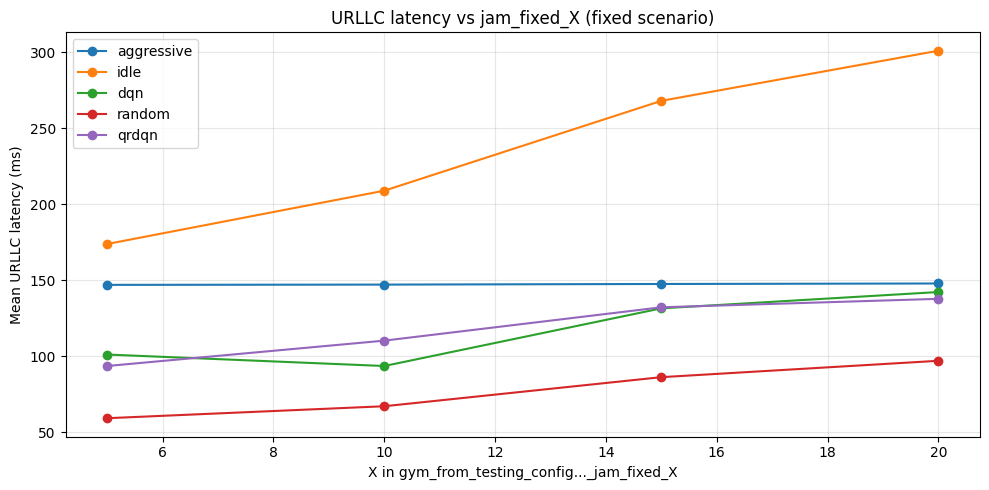

In [21]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT   = Path("../../tb_logs/res_validator")
POLICIES  = ["aggressive", "idle", "dqn", "random", "qrdqn"]
X_VALUES  = [5, 10, 15, 20]
LAT_TAG   = "latency/urllc"   # change if needed
SECONDS_TO_MS = 1000.0
WARMUP_STEPS = 0
USE_MEDIAN = False

FIXED_RE = re.compile(r"jam_fixed[_\-]?(\d+)", re.IGNORECASE)

def find_policy_from_path(p: Path):
    parts = [x.lower() for x in p.parts]
    for pol in POLICIES:
        if pol.lower() in parts:
            return pol
    return None

def find_fixed_x_and_group_dir(event_file: Path, max_up=12):
    """
    Walk up ancestors to find the folder that contains jam_fixed_X.
    Returns (x, group_dir) where group_dir is the jam_fixed_X directory.
    """
    cur = event_file.parent  # directory containing the event file
    for _ in range(max_up):
        m = FIXED_RE.search(cur.name)
        if m:
            x = int(m.group(1))
            return x, cur
        if cur.parent == cur:
            break
        cur = cur.parent
    return None, None

def read_scalar_mean_ms(event_dir: Path, tag: str):
    """
    IMPORTANT: event_dir must be the directory that actually contains events.out.tfevents.*
    """
    try:
        ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
        ea.Reload()

        if tag not in ea.Tags().get("scalars", []):
            return np.nan

        events = ea.Scalars(tag)
        steps = np.array([e.step for e in events], dtype=int)
        vals  = np.array([e.value for e in events], dtype=float)

        vals = vals[steps >= WARMUP_STEPS]
        if len(vals) == 0:
            return np.nan

        vals_ms = vals * SECONDS_TO_MS
        return float(np.nanmedian(vals_ms) if USE_MEDIAN else np.nanmean(vals_ms))
    except Exception:
        return np.nan

# ----------------------------
# Scan all event files
# ----------------------------
event_files = list(TB_ROOT.rglob("events.out.tfevents.*"))
print("Event files found:", len(event_files))

rows = []

for ev in event_files:
    policy = find_policy_from_path(ev)
    if policy is None:
        continue

    x, group_dir = find_fixed_x_and_group_dir(ev)
    if x is None or x not in X_VALUES:
        continue

    # Read scalars from the directory that *contains the event file*
    event_dir = ev.parent
    lat_ms = read_scalar_mean_ms(event_dir, LAT_TAG)

    rows.append({
        "policy": policy,
        "x": x,
        "group_dir": str(group_dir),   # .../gym_from_testing_config..._jam_fixed_X
        "event_dir": str(event_dir),   # .../gym_from..._jam_fixed_X/<run_subdir>
        "mean_latency_ms": lat_ms,
    })

df = pd.DataFrame(rows)
df = df.dropna(subset=["mean_latency_ms"])

print("Matched fixed runs (rows):", len(df))
display(df.sort_values(["policy","x"]).head(20))

# Aggregate in case you have multiple runs per policy/x
agg = (df.groupby(["policy","x"], as_index=False)
         .agg(mean_latency_ms=("mean_latency_ms","mean"),
              std_latency_ms=("mean_latency_ms","std"),
              n=("mean_latency_ms","count")))

display(agg.sort_values(["policy","x"]))

# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(10,5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["mean_latency_ms"], marker="o", label=pol)

plt.title("URLLC latency vs jam_fixed_X (fixed scenario)")
plt.xlabel("X in gym_from_testing_config..._jam_fixed_X")
plt.ylabel("Mean URLLC latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Baseline folder: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator/idle__20260120_092923__res18_off0_const0_per2500_dur1250
Baseline event files: 1
Baseline mean URLLC latency: 137.733 ms (computed from 1 event files)
Matched jam_fixed rows: 20


,policy,x,jam_latency_ms,delta_latency_ms,event_dir
16,aggressive,5,146.943985,9.210678,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
19,aggressive,10,147.121448,9.388141,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
17,aggressive,15,147.527818,9.794511,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
18,aggressive,20,147.855425,10.122118,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
12,dqn,5,101.057005,-36.676302,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
15,dqn,10,93.498812,-44.234495,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
13,dqn,15,131.483107,-6.250200,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
14,dqn,20,142.230292,4.496984,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
8,idle,5,173.860991,36.127683,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
11,idle,10,208.978170,71.244863,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...


,policy,x,jam_latency_ms,delta_latency_ms,n,delta_std
0,aggressive,5,146.943985,9.210678,1,NaN
1,aggressive,10,147.121448,9.388141,1,NaN
2,aggressive,15,147.527818,9.794511,1,NaN
3,aggressive,20,147.855425,10.122118,1,NaN
4,dqn,5,101.057005,-36.676302,1,NaN
5,dqn,10,93.498812,-44.234495,1,NaN
6,dqn,15,131.483107,-6.250200,1,NaN
7,dqn,20,142.230292,4.496984,1,NaN
8,idle,5,173.860991,36.127683,1,NaN
9,idle,10,208.978170,71.244863,1,NaN


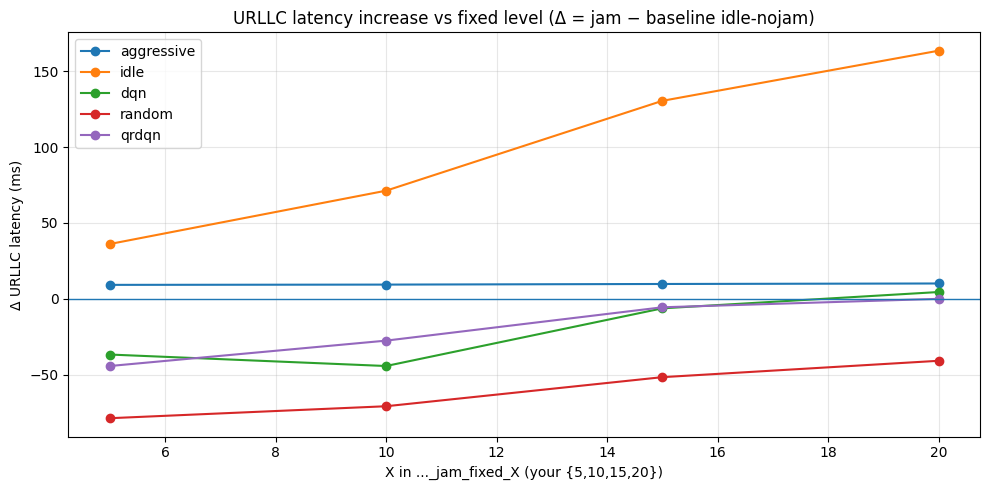

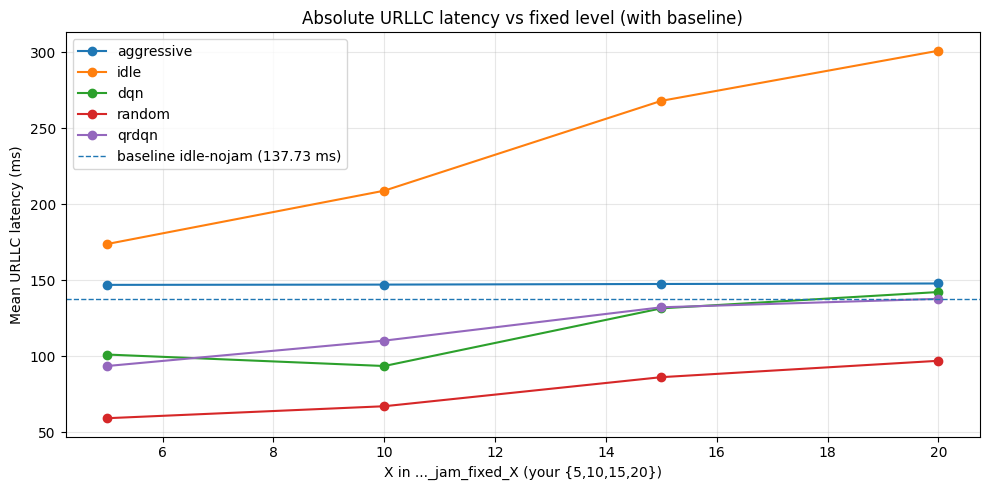

In [24]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT = Path("/home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator")

BASELINE_DIRNAME = "idle__20260120_092923__res18_off0_const0_per2500_dur1250"  # your no-jam baseline folder
POLICIES = ["aggressive", "idle", "dqn", "random", "qrdqn"]
X_VALUES = [5, 10, 15, 20]                 # the trailing number in ..._jam_fixed_X
LAT_TAG  = "latency/urllc"                 # change if your TB tag differs
SECONDS_TO_MS = 1000.0
WARMUP_STEPS = 0                           # set >0 to ignore early steps
USE_MEDIAN = False                         # True -> median instead of mean

FIXED_RE = re.compile(r"jam_fixed[_\-]?(\d+)", re.IGNORECASE)

# ----------------------------
# Helpers
# ----------------------------
def read_latency_ms_from_event_dir(event_dir: Path, tag: str) -> float:
    """EventAccumulator must point to a directory that CONTAINS events.out.tfevents.*"""
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        return np.nan
    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)

    vals = vals[steps >= WARMUP_STEPS]
    if len(vals) == 0:
        return np.nan

    vals_ms = vals * SECONDS_TO_MS
    return float(np.nanmedian(vals_ms) if USE_MEDIAN else np.nanmean(vals_ms))

def find_policy_from_path(p: Path):
    parts = [x.lower() for x in p.parts]
    for pol in POLICIES:
        if pol.lower() in parts:
            return pol
    return None

def find_fixed_x(ev_path: Path, max_up=12):
    """Walk up to find an ancestor folder name containing jam_fixed_X."""
    cur = ev_path.parent
    for _ in range(max_up):
        m = FIXED_RE.search(cur.name)
        if m:
            return int(m.group(1))
        if cur.parent == cur:
            break
        cur = cur.parent
    return None

# ----------------------------
# 1) Compute baseline latency (no-jam idle)
# ----------------------------
baseline_root = TB_ROOT / BASELINE_DIRNAME
baseline_events = list(baseline_root.rglob("events.out.tfevents.*"))

print("Baseline folder:", baseline_root)
print("Baseline event files:", len(baseline_events))

if len(baseline_events) == 0:
    raise RuntimeError("No event files found in baseline folder. Check BASELINE_DIRNAME.")

# baseline event dir is the parent of the event file
baseline_ms_list = []
for ev in baseline_events:
    baseline_ms_list.append(read_latency_ms_from_event_dir(ev.parent, LAT_TAG))

baseline_ms_list = [x for x in baseline_ms_list if not np.isnan(x)]
if len(baseline_ms_list) == 0:
    raise RuntimeError(f"Baseline found event files but no '{LAT_TAG}' scalar tag. Check LAT_TAG.")

baseline_ms = float(np.mean(baseline_ms_list))
print(f"Baseline mean URLLC latency: {baseline_ms:.3f} ms (computed from {len(baseline_ms_list)} event files)")

# ----------------------------
# 2) Collect jam_fixed_X runs for all policies
# ----------------------------
event_files = list(TB_ROOT.rglob("events.out.tfevents.*"))
rows = []

for ev in event_files:
    # skip baseline folder events
    if BASELINE_DIRNAME in str(ev):
        continue

    policy = find_policy_from_path(ev)
    if policy is None:
        continue

    x = find_fixed_x(ev)
    if x is None or x not in X_VALUES:
        continue

    jam_ms = read_latency_ms_from_event_dir(ev.parent, LAT_TAG)
    if np.isnan(jam_ms):
        continue

    rows.append({
        "policy": policy,
        "x": x,
        "jam_latency_ms": jam_ms,
        "delta_latency_ms": jam_ms - baseline_ms,
        "event_dir": str(ev.parent),
    })

df = pd.DataFrame(rows)
print("Matched jam_fixed rows:", len(df))
display(df.sort_values(["policy", "x"]).head(30))

# Aggregate if multiple runs exist per (policy, x)
agg = (df.groupby(["policy", "x"], as_index=False)
         .agg(jam_latency_ms=("jam_latency_ms", "mean"),
              delta_latency_ms=("delta_latency_ms", "mean"),
              n=("delta_latency_ms", "count"),
              delta_std=("delta_latency_ms", "std")))

display(agg.sort_values(["policy", "x"]))

# ----------------------------
# 3) Plot Δ latency vs fixed level (one line per policy)
# ----------------------------
plt.figure(figsize=(10, 5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["delta_latency_ms"], marker="o", label=pol)

plt.axhline(0.0, linewidth=1)
plt.title("URLLC latency increase vs fixed level (Δ = jam − baseline idle-nojam)")
plt.xlabel("X in ..._jam_fixed_X (your {5,10,15,20})")
plt.ylabel("Δ URLLC latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# (Optional) also plot absolute jam latency for reference
plt.figure(figsize=(10, 5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["jam_latency_ms"], marker="o", label=pol)

plt.axhline(baseline_ms, linestyle="--", linewidth=1, label=f"baseline idle-nojam ({baseline_ms:.2f} ms)")
plt.title("Absolute URLLC latency vs fixed level (with baseline)")
plt.xlabel("X in ..._jam_fixed_X (your {5,10,15,20})")
plt.ylabel("Mean URLLC latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


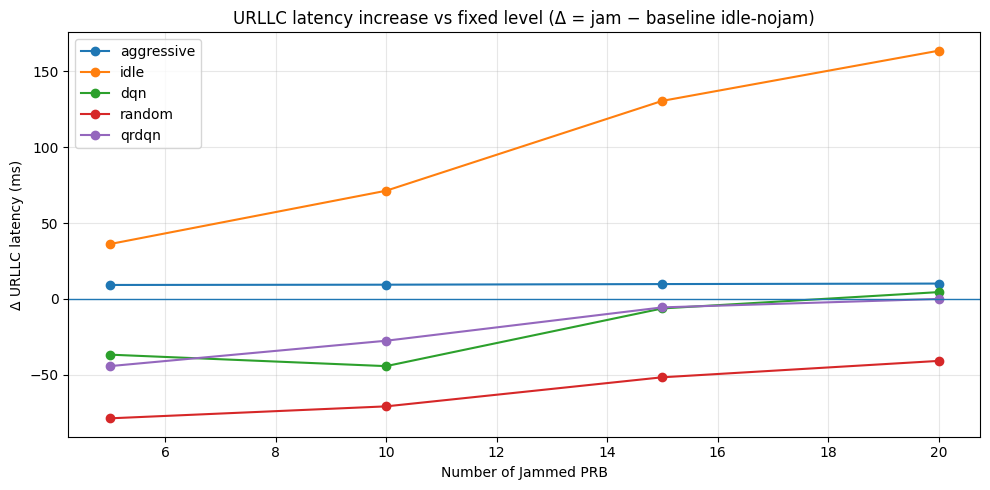

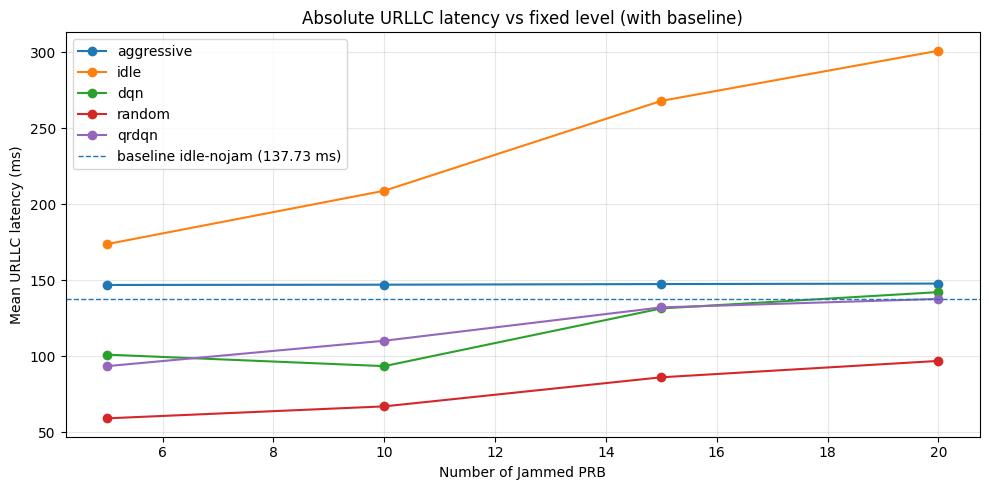

In [25]:
# ----------------------------
# 3) Plot Δ latency vs fixed level (one line per policy)
# ----------------------------
plt.figure(figsize=(10, 5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["delta_latency_ms"], marker="o", label=pol)

plt.axhline(0.0, linewidth=1)
plt.title("URLLC latency increase vs fixed level (Δ = jam − baseline idle-nojam)")
plt.xlabel("Number of Jammed PRB")
plt.ylabel("Δ URLLC latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# (Optional) also plot absolute jam latency for reference
plt.figure(figsize=(10, 5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["jam_latency_ms"], marker="o", label=pol)

plt.axhline(baseline_ms, linestyle="--", linewidth=1, label=f"baseline idle-nojam ({baseline_ms:.2f} ms)")
plt.title("Absolute URLLC latency vs fixed level (with baseline)")
plt.xlabel("Number of Jammed PRB")
plt.ylabel("Mean URLLC latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

Baseline event files: 1
Using throughput tag: throughput/embb_mbps
Baseline mean throughput (embb): 94.688
Matched jam_fixed rows: 20


,policy,x,throughput_jam,throughput_drop,event_dir
16,aggressive,5,94.741056,-0.053489,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
19,aggressive,10,94.742333,-0.054765,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
17,aggressive,15,94.733292,-0.045725,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
18,aggressive,20,94.644940,0.042628,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
12,dqn,5,95.196654,-0.509086,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
15,dqn,10,94.903781,-0.216213,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
13,dqn,15,94.746342,-0.058775,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
14,dqn,20,94.431837,0.255730,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
8,idle,5,94.505453,0.182114,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
11,idle,10,94.164920,0.522647,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...


,policy,x,throughput_jam,throughput_drop,drop_std,n
0,aggressive,5,94.741056,-0.053489,NaN,1
1,aggressive,10,94.742333,-0.054765,NaN,1
2,aggressive,15,94.733292,-0.045725,NaN,1
3,aggressive,20,94.644940,0.042628,NaN,1
4,dqn,5,95.196654,-0.509086,NaN,1
5,dqn,10,94.903781,-0.216213,NaN,1
6,dqn,15,94.746342,-0.058775,NaN,1
7,dqn,20,94.431837,0.255730,NaN,1
8,idle,5,94.505453,0.182114,NaN,1
9,idle,10,94.164920,0.522647,NaN,1


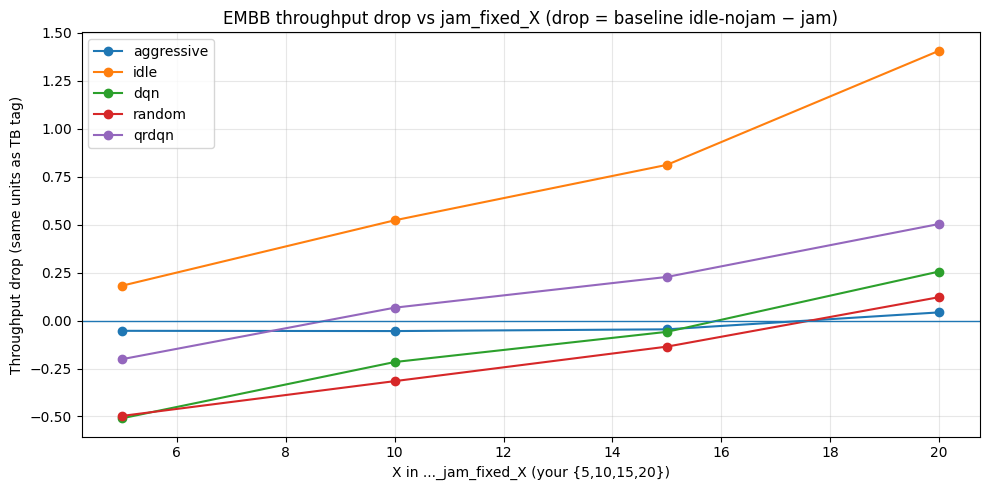

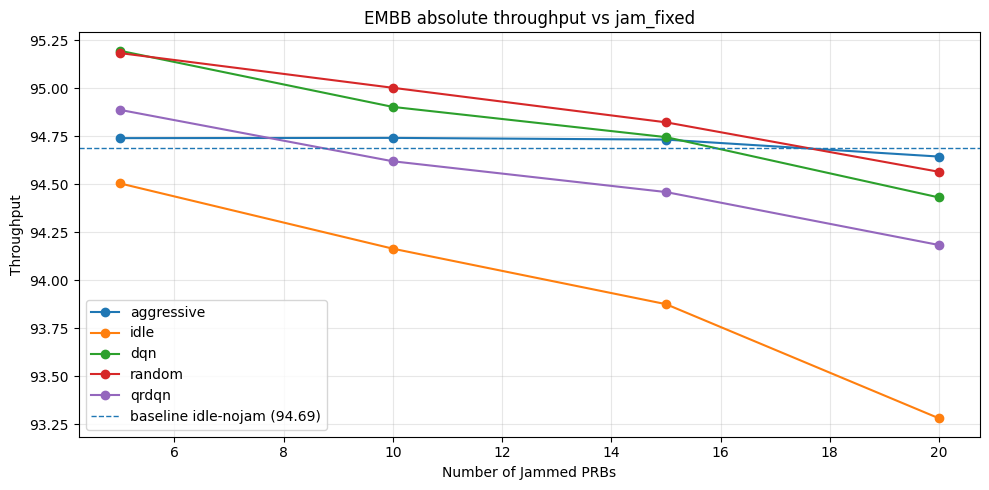

In [33]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT = Path("/home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator")

BASELINE_DIRNAME = "idle__20260120_092923__res18_off0_const0_per2500_dur1250"
POLICIES = ["aggressive", "idle", "dqn", "random", "qrdqn"]
X_VALUES = [5, 10, 15, 20]

# Choose which throughput you want to plot:
# "embb" or "urllc"
SLICE = "embb"

# If you know your exact TB tag, set it here and skip autodetect by setting USE_AUTODETECT=False
USE_AUTODETECT = True
THR_TAG = None  # e.g., "throughput/urllc_mbps" or "throughput/embb_mbps"

# Candidate tags (edit if yours differ)
THR_TAG_CANDIDATES = {
    "embb":  ["throughput/embb_mbps", "throughput/embb", "embb/throughput_mbps", "kpi/embb_throughput_mbps"],
    "urllc": ["throughput/urllc_mbps", "throughput/urllc", "urllc/throughput_mbps", "kpi/urllc_throughput_mbps"],
}

WARMUP_STEPS = 0
USE_MEDIAN = False

FIXED_RE = re.compile(r"jam_fixed[_\-]?(\d+)", re.IGNORECASE)

# ----------------------------
# Helpers
# ----------------------------
def read_scalar_mean(event_dir: Path, tag: str) -> float:
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        return np.nan

    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)

    vals = vals[steps >= WARMUP_STEPS]
    if len(vals) == 0:
        return np.nan

    return float(np.nanmedian(vals) if USE_MEDIAN else np.nanmean(vals))

def autodetect_tag(event_dir: Path, candidates: list[str]) -> str | None:
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    available = set(ea.Tags().get("scalars", []))
    for c in candidates:
        if c in available:
            return c
    return None

def find_policy_from_path(p: Path):
    parts = [x.lower() for x in p.parts]
    for pol in POLICIES:
        if pol.lower() in parts:
            return pol
    return None

def find_fixed_x(ev_path: Path, max_up=12):
    cur = ev_path.parent
    for _ in range(max_up):
        m = FIXED_RE.search(cur.name)
        if m:
            return int(m.group(1))
        if cur.parent == cur:
            break
        cur = cur.parent
    return None

# ----------------------------
# 1) Baseline throughput (idle no-jam)
# ----------------------------
baseline_root = TB_ROOT / BASELINE_DIRNAME
baseline_events = list(baseline_root.rglob("events.out.tfevents.*"))
print("Baseline event files:", len(baseline_events))
if len(baseline_events) == 0:
    raise RuntimeError("No event files found in baseline folder. Check BASELINE_DIRNAME.")

# choose a baseline event_dir to autodetect tag
baseline_event_dir0 = baseline_events[0].parent

if USE_AUTODETECT:
    tag = autodetect_tag(baseline_event_dir0, THR_TAG_CANDIDATES[SLICE])
    if tag is None:
        # Print available tags to help you set THR_TAG manually
        ea = EventAccumulator(str(baseline_event_dir0), size_guidance={"scalars": 0})
        ea.Reload()
        print("Available scalar tags (baseline):")
        print(sorted(ea.Tags().get("scalars", []))[:80])
        raise RuntimeError("Could not auto-detect throughput tag. Set THR_TAG manually.")
    THR_TAG = tag

print("Using throughput tag:", THR_TAG)

base_vals = []
for ev in baseline_events:
    v = read_scalar_mean(ev.parent, THR_TAG)
    if not np.isnan(v):
        base_vals.append(v)

if len(base_vals) == 0:
    raise RuntimeError(f"Baseline has events but tag '{THR_TAG}' is missing/empty.")
T_base = float(np.mean(base_vals))
print(f"Baseline mean throughput ({SLICE}): {T_base:.3f}")

# ----------------------------
# 2) Collect jam_fixed_X throughput for all policies
# ----------------------------
event_files = list(TB_ROOT.rglob("events.out.tfevents.*"))
rows = []

for ev in event_files:
    if BASELINE_DIRNAME in str(ev):
        continue

    policy = find_policy_from_path(ev)
    if policy is None:
        continue

    x = find_fixed_x(ev)
    if x is None or x not in X_VALUES:
        continue

    T_jam = read_scalar_mean(ev.parent, THR_TAG)
    if np.isnan(T_jam):
        continue

    rows.append({
        "policy": policy,
        "x": x,
        "throughput_jam": T_jam,
        "throughput_drop": T_base - T_jam,   # positive means throughput got worse
        "event_dir": str(ev.parent),
    })

df = pd.DataFrame(rows)
print("Matched jam_fixed rows:", len(df))
display(df.sort_values(["policy","x"]).head(30))

agg = (df.groupby(["policy","x"], as_index=False)
         .agg(throughput_jam=("throughput_jam","mean"),
              throughput_drop=("throughput_drop","mean"),
              drop_std=("throughput_drop","std"),
              n=("throughput_drop","count")))

display(agg.sort_values(["policy","x"]))

# ----------------------------
# 3) Plot throughput DROP vs X (one line per policy)
# ----------------------------
plt.figure(figsize=(10,5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["throughput_drop"], marker="o", label=pol)

plt.axhline(0.0, linewidth=1)
plt.title(f"{SLICE.upper()} throughput drop vs jam_fixed_X (drop = baseline idle-nojam − jam)")
plt.xlabel("X in ..._jam_fixed_X (your {5,10,15,20})")
plt.ylabel("Throughput drop (same units as TB tag)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# (Optional) Plot absolute throughput with baseline reference
plt.figure(figsize=(10,5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["throughput_jam"], marker="o", label=pol)

plt.axhline(T_base, linestyle="--", linewidth=1, label=f"baseline idle-nojam ({T_base:.2f})")
plt.title(f"{SLICE.upper()} absolute throughput vs jam_fixed")
plt.xlabel("Number of Jammed PRBs")
plt.ylabel("Throughput")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Baseline event files: 1
Using PRB tag: obs/reserve_used_prb
Baseline mean PRB metric: 0.000
Matched jam_fixed rows: 20


,policy,x,prb_jam,prb_increase,event_dir
16,aggressive,5,2.497497,2.497497,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
19,aggressive,10,5.039039,5.039039,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
17,aggressive,15,7.492492,7.492492,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
18,aggressive,20,8.990991,8.990991,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
12,dqn,5,4.972072,4.972072,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
15,dqn,10,5.659219,5.659219,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
13,dqn,15,6.635696,6.635696,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
14,dqn,20,7.216877,7.216877,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
8,idle,5,0.000000,0.000000,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...
11,idle,10,0.000000,0.000000,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...


,policy,x,prb_jam,prb_increase,inc_std,n
0,aggressive,5,2.497497,2.497497,NaN,1
1,aggressive,10,5.039039,5.039039,NaN,1
2,aggressive,15,7.492492,7.492492,NaN,1
3,aggressive,20,8.990991,8.990991,NaN,1
4,dqn,5,4.972072,4.972072,NaN,1
5,dqn,10,5.659219,5.659219,NaN,1
6,dqn,15,6.635696,6.635696,NaN,1
7,dqn,20,7.216877,7.216877,NaN,1
8,idle,5,0.000000,0.000000,NaN,1
9,idle,10,0.000000,0.000000,NaN,1


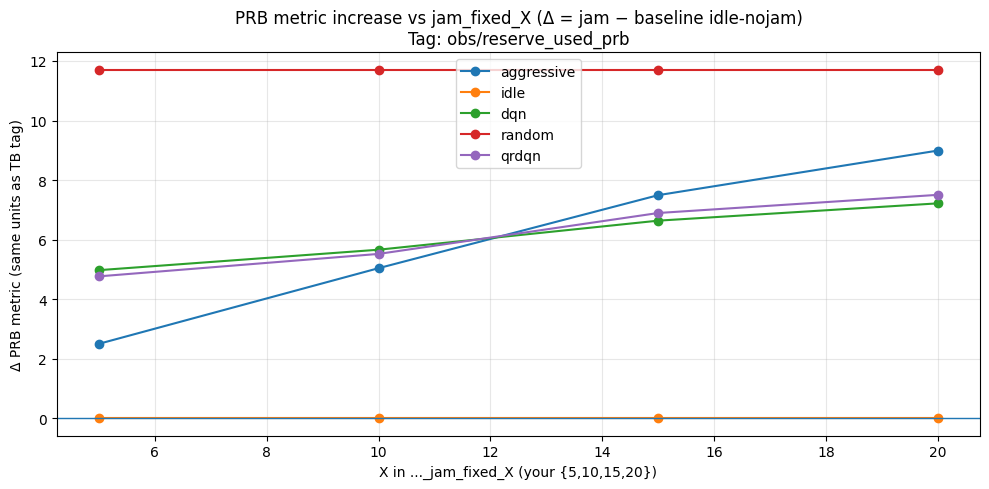

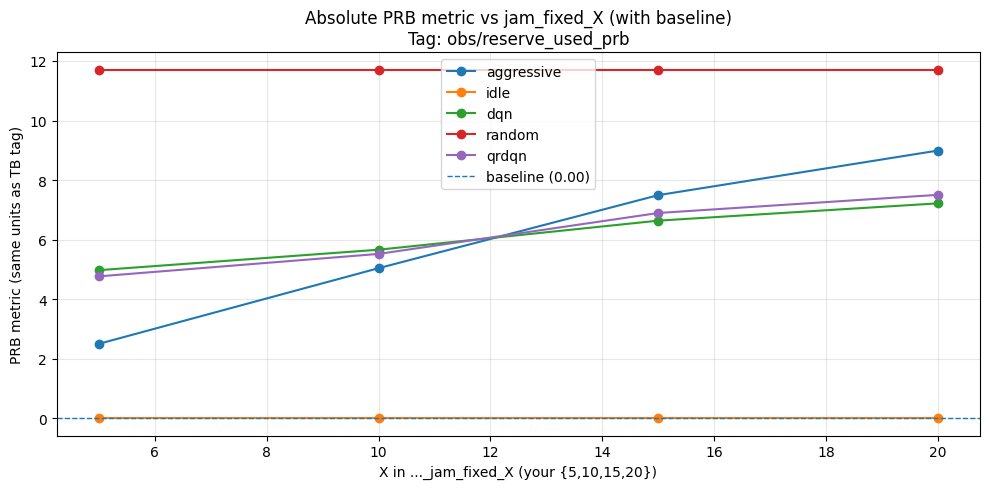

In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT = Path("/home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator")

BASELINE_DIRNAME = "idle__20260120_092923__res18_off0_const0_per2500_dur1250"
POLICIES = ["aggressive", "idle", "dqn", "random", "qrdqn"]
X_VALUES = [5, 10, 15, 20]

# If you KNOW the exact PRB tag, set it here and set USE_AUTODETECT=False
USE_AUTODETECT = False
PRB_TAG = "obs/reserve_used_prb"  # e.g. "prb/total_used", "prb/reserve_used", "action/sum" etc.

# Autodetect keywords: we will pick the first scalar tag that matches these
PRB_KEYWORDS = ["prb", "prbs", "rb", "resource_block", "resourceblock", "reserved", "reserve"]

WARMUP_STEPS = 0
USE_MEDIAN = False

FIXED_RE = re.compile(r"jam_fixed[_\-]?(\d+)", re.IGNORECASE)

# ----------------------------
# Helpers
# ----------------------------
def load_scalars(event_dir: Path):
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    return ea

def read_scalar_mean(event_dir: Path, tag: str) -> float:
    ea = load_scalars(event_dir)
    if tag not in ea.Tags().get("scalars", []):
        return np.nan

    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)

    vals = vals[steps >= WARMUP_STEPS]
    if len(vals) == 0:
        return np.nan

    return float(np.nanmedian(vals) if USE_MEDIAN else np.nanmean(vals))

def find_policy_from_path(p: Path):
    parts = [x.lower() for x in p.parts]
    for pol in POLICIES:
        if pol.lower() in parts:
            return pol
    return None

def find_fixed_x(ev_path: Path, max_up=12):
    cur = ev_path.parent
    for _ in range(max_up):
        m = FIXED_RE.search(cur.name)
        if m:
            return int(m.group(1))
        if cur.parent == cur:
            break
        cur = cur.parent
    return None

def autodetect_prb_tag(event_dir: Path):
    ea = load_scalars(event_dir)
    tags = ea.Tags().get("scalars", [])
    tags_l = [t.lower() for t in tags]

    # Prefer tags that contain "prb" explicitly
    candidates = []
    for t, tl in zip(tags, tags_l):
        if any(k in tl for k in PRB_KEYWORDS):
            candidates.append(t)

    # Heuristic preference order (edit if you want)
    prefer = [
        "reserve", "reserved", "pool", "total", "used", "usage", "alloc", "allocation", "action/sum"
    ]
    candidates.sort(key=lambda t: sum(p in t.lower() for p in prefer), reverse=True)

    return candidates[0] if candidates else None

# ----------------------------
# 1) Baseline PRB usage
# ----------------------------
baseline_root = TB_ROOT / BASELINE_DIRNAME
baseline_events = list(baseline_root.rglob("events.out.tfevents.*"))
print("Baseline event files:", len(baseline_events))
if len(baseline_events) == 0:
    raise RuntimeError("No event files found in baseline folder. Check BASELINE_DIRNAME.")

baseline_event_dir0 = baseline_events[0].parent

if USE_AUTODETECT:
    PRB_TAG = autodetect_prb_tag(baseline_event_dir0)
    if PRB_TAG is None:
        ea = load_scalars(baseline_event_dir0)
        print("Available scalar tags (baseline):")
        print(sorted(ea.Tags().get("scalars", []))[:120])
        raise RuntimeError("Could not auto-detect a PRB-related scalar tag. Set PRB_TAG manually.")
else:
    if PRB_TAG is None:
        raise RuntimeError("Set PRB_TAG or enable USE_AUTODETECT.")

print("Using PRB tag:", PRB_TAG)

base_vals = []
for ev in baseline_events:
    v = read_scalar_mean(ev.parent, PRB_TAG)
    if not np.isnan(v):
        base_vals.append(v)

if len(base_vals) == 0:
    raise RuntimeError(f"Baseline has events but tag '{PRB_TAG}' is missing/empty.")

PRB_base = float(np.mean(base_vals))
print(f"Baseline mean PRB metric: {PRB_base:.3f}")

# ----------------------------
# 2) Collect jam_fixed_X PRB usage for all policies
# ----------------------------
event_files = list(TB_ROOT.rglob("events.out.tfevents.*"))
rows = []

for ev in event_files:
    if BASELINE_DIRNAME in str(ev):
        continue

    policy = find_policy_from_path(ev)
    if policy is None:
        continue

    x = find_fixed_x(ev)
    if x is None or x not in X_VALUES:
        continue

    prb_jam = read_scalar_mean(ev.parent, PRB_TAG)
    if np.isnan(prb_jam):
        continue

    rows.append({
        "policy": policy,
        "x": x,
        "prb_jam": prb_jam,
        "prb_increase": prb_jam - PRB_base,  # positive means "uses more PRBs than baseline"
        "event_dir": str(ev.parent),
    })

df = pd.DataFrame(rows)
print("Matched jam_fixed rows:", len(df))
display(df.sort_values(["policy","x"]).head(30))

agg = (df.groupby(["policy","x"], as_index=False)
         .agg(prb_jam=("prb_jam","mean"),
              prb_increase=("prb_increase","mean"),
              inc_std=("prb_increase","std"),
              n=("prb_increase","count")))

display(agg.sort_values(["policy","x"]))

# ----------------------------
# 3) Plot PRB increase vs X
# ----------------------------
plt.figure(figsize=(10,5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["prb_increase"], marker="o", label=pol)

plt.axhline(0.0, linewidth=1)
plt.title(f"PRB metric increase vs jam_fixed_X (Δ = jam − baseline idle-nojam)\nTag: {PRB_TAG}")
plt.xlabel("Number of Jammed PRBs")
plt.ylabel("Δ PRB metric (number of PRBs used under jamming)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Optional: absolute PRB metric
plt.figure(figsize=(10,5))
for pol in POLICIES:
    sub = agg[agg["policy"] == pol].sort_values("x")
    if sub.empty:
        continue
    plt.plot(sub["x"], sub["prb_jam"], marker="o", label=pol)

plt.axhline(PRB_base, linestyle="--", linewidth=1, label=f"baseline ({PRB_base:.2f})")
plt.title(f"Absolute PRB metric vs jam_fixed_X (with baseline)\nTag: {PRB_TAG}")
plt.xlabel("X in ..._jam_fixed_X (your {5,10,15,20})")
plt.ylabel("PRB metric (same units as TB tag)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


policy=aggressive baseline: latency=137.733 ms, thr=40.455 (throughput/urllc_mbps)
policy=idle baseline: latency=137.733 ms, thr=40.455 (throughput/urllc_mbps)
policy=dqn baseline: latency=94.168 ms, thr=40.854 (throughput/urllc_mbps)
policy=random baseline: latency=46.230 ms, thr=41.216 (throughput/urllc_mbps)
policy=qrdqn baseline: latency=69.902 ms, thr=41.028 (throughput/urllc_mbps)


,policy,severity,baseline_lat_ms,baseline_thr,jam_lat_ms,jam_thr,delta_L_jam_ms,delta_T_drop,run_folder
0,aggressive,5,137.733307,40.455411,129.402536,40.271873,-8.330771,0.183538,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
3,aggressive,10,137.733307,40.455411,129.595947,40.266187,-8.137361,0.189224,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10
1,aggressive,15,137.733307,40.455411,130.083542,40.246067,-7.649766,0.209345,gym_from_testing_config_1ms_10s_8UE_jam_fixed_15
2,aggressive,20,137.733307,40.455411,130.489663,40.242088,-7.243645,0.213323,gym_from_testing_config_1ms_10s_8UE_jam_fixed_20
8,dqn,5,94.168280,40.854258,89.988186,40.673809,-4.180094,0.180450,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
11,dqn,10,94.168280,40.854258,83.532680,40.594388,-10.635600,0.259871,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10
9,dqn,15,94.168280,40.854258,117.304368,40.021287,23.136088,0.832971,gym_from_testing_config_1ms_10s_8UE_jam_fixed_15
10,dqn,20,94.168280,40.854258,125.992241,39.794389,31.823961,1.059870,gym_from_testing_config_1ms_10s_8UE_jam_fixed_20
4,idle,5,137.733307,40.455411,153.594184,39.825233,15.860876,0.630178,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
7,idle,10,137.733307,40.455411,184.764616,39.224815,47.031308,1.230596,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10


,policy,severity,delta_L_jam_ms,delta_T_drop,n
0,aggressive,5,-8.330771,0.183538,1
1,aggressive,10,-8.137361,0.189224,1
2,aggressive,15,-7.649766,0.209345,1
3,aggressive,20,-7.243645,0.213323,1
4,dqn,5,-4.180094,0.180450,1
5,dqn,10,-10.635600,0.259871,1
6,dqn,15,23.136088,0.832971,1
7,dqn,20,31.823961,1.059870,1
8,idle,5,15.860876,0.630178,1
9,idle,10,47.031308,1.230596,1


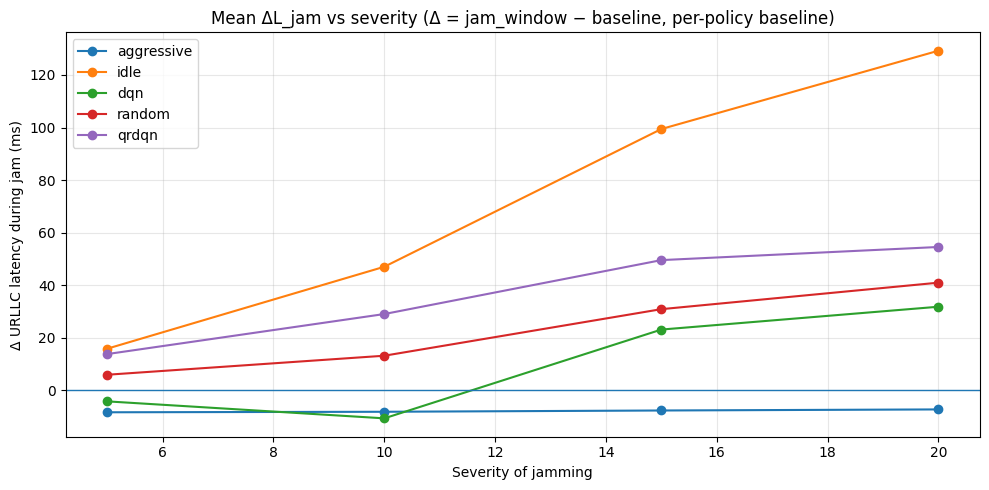

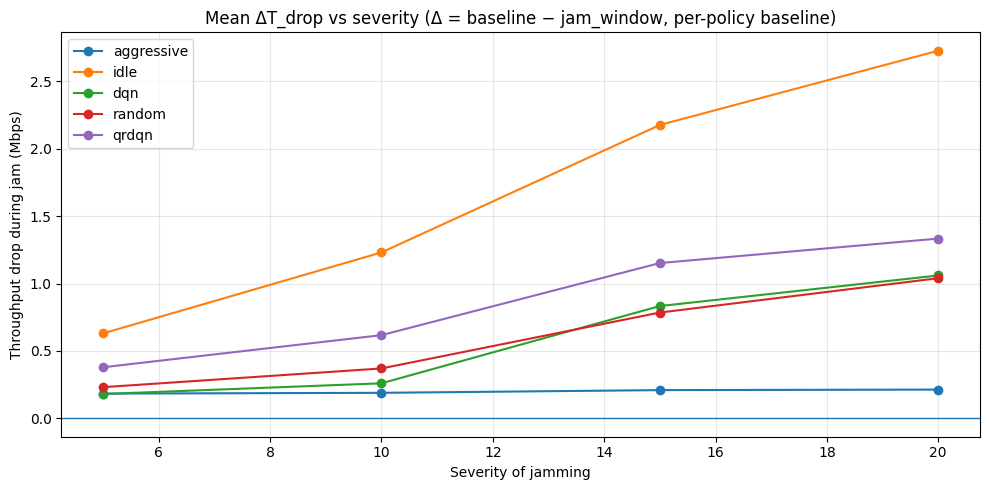

In [35]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT = Path("/home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator")

POLICIES  = ["aggressive", "idle", "dqn", "random", "qrdqn"]
SEVERITY  = [5, 10, 15, 20]  # your jam_fixed_5/10/15/20

BASELINE_FOLDER_REGEX = re.compile(r"jam_fixed_baseline_0$", re.IGNORECASE)
FIXED_FOLDER_REGEX    = re.compile(r"jam_fixed_(\d+)$", re.IGNORECASE)

EFF_TAG = "prb/effective_ratio"
LAT_TAG = "latency/urllc"          # assumed seconds -> ms
THR_TAG = "throughput/urllc_mbps"  # change to throughput/embb_mbps if needed

# Jam detection
JAM_THRESH = 0.999   # jam ON if effective_ratio < this
WARMUP_STEPS = 0     # ignore first N steps if you want (e.g., 10)

# Stats
USE_MEDIAN = False   # True uses median instead of mean
LAT_IN_SECONDS = True  # set False if latency already in ms in TB

# ----------------------------
# Helpers
# ----------------------------
def event_dirs_under(run_root: Path):
    """Return all directories that directly contain events.out.tfevents.* under this run_root."""
    evs = list(run_root.rglob("events.out.tfevents.*"))
    return sorted({p.parent for p in evs})

def load_series(event_dir: Path, tag: str):
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        return None
    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)
    m = steps >= WARMUP_STEPS
    return steps[m], vals[m]

def align_on_steps(series_dict):
    """series_dict: {col: (steps, vals)} -> dataframe joined on common steps."""
    dfs = []
    for col, sv in series_dict.items():
        if sv is None:
            return None
        s, v = sv
        dfs.append(pd.DataFrame({"step": s, col: v}).set_index("step"))
    df = pd.concat(dfs, axis=1, join="inner").sort_index()
    return df if not df.empty else None

def agg_stat(x):
    return float(np.nanmedian(x) if USE_MEDIAN else np.nanmean(x))

def mean_metrics_in_window(event_dir: Path, jam_only: bool):
    """
    Returns (lat_ms, thr) averaged either during jam_only or over all samples.
    Jam is detected using effective_ratio < JAM_THRESH.
    """
    s_eff = load_series(event_dir, EFF_TAG)
    s_lat = load_series(event_dir, LAT_TAG)
    s_thr = load_series(event_dir, THR_TAG)
    df = align_on_steps({"eff": s_eff, "lat": s_lat, "thr": s_thr})
    if df is None:
        return np.nan, np.nan

    if LAT_IN_SECONDS:
        df["lat_ms"] = df["lat"] * 1000.0
    else:
        df["lat_ms"] = df["lat"]

    if jam_only:
        mask = df["eff"].values < JAM_THRESH
        if mask.sum() == 0:
            return np.nan, np.nan
        lat_ms = agg_stat(df.loc[mask, "lat_ms"].values)
        thr    = agg_stat(df.loc[mask, "thr"].values)
    else:
        lat_ms = agg_stat(df["lat_ms"].values)
        thr    = agg_stat(df["thr"].values)

    return lat_ms, thr

def collect_run_stats(run_root: Path, jam_only: bool):
    """
    A run_root can contain multiple event dirs (subruns). Compute metric per event_dir then average.
    """
    edirs = event_dirs_under(run_root)
    if not edirs:
        return np.nan, np.nan

    lats, thrs = [], []
    for ed in edirs:
        lat_ms, thr = mean_metrics_in_window(ed, jam_only=jam_only)
        if not np.isnan(lat_ms):
            lats.append(lat_ms)
        if not np.isnan(thr):
            thrs.append(thr)

    if len(lats) == 0 or len(thrs) == 0:
        return np.nan, np.nan

    return float(np.mean(lats)), float(np.mean(thrs))

# ----------------------------
# Main: per policy baseline + severity metrics
# ----------------------------
rows = []

for policy in POLICIES:
    pol_dir = TB_ROOT / policy
    if not pol_dir.exists():
        continue

    # find baseline folder inside policy dir
    baseline_folders = [p for p in pol_dir.iterdir() if p.is_dir() and BASELINE_FOLDER_REGEX.search(p.name)]
    if len(baseline_folders) == 0:
        print(f"[WARN] No baseline folder found for policy={policy}")
        continue
    baseline_root = baseline_folders[0]

    # baseline metrics (no-jam): average over all samples
    base_lat_ms, base_thr = collect_run_stats(baseline_root, jam_only=False)
    if np.isnan(base_lat_ms) or np.isnan(base_thr):
        print(f"[WARN] Baseline metrics missing for policy={policy} in {baseline_root.name}")
        continue

    print(f"policy={policy} baseline: latency={base_lat_ms:.3f} ms, thr={base_thr:.3f} ({THR_TAG})")

    # severity folders: jam_fixed_5/10/15/20
    for p in pol_dir.iterdir():
        if not p.is_dir():
            continue
        m = FIXED_FOLDER_REGEX.search(p.name)
        if not m:
            continue
        sev = int(m.group(1))
        if sev not in SEVERITY:
            continue

        jam_lat_ms, jam_thr = collect_run_stats(p, jam_only=True)
        if np.isnan(jam_lat_ms) or np.isnan(jam_thr):
            continue

        rows.append({
            "policy": policy,
            "severity": sev,
            "baseline_lat_ms": base_lat_ms,
            "baseline_thr": base_thr,
            "jam_lat_ms": jam_lat_ms,
            "jam_thr": jam_thr,
            "delta_L_jam_ms": jam_lat_ms - base_lat_ms,      # higher = worse
            "delta_T_drop": base_thr - jam_thr,              # higher = worse
            "run_folder": p.name,
        })

df = pd.DataFrame(rows)
display(df.sort_values(["policy","severity"]))

# Aggregate in case multiple runs exist per point
agg = (df.groupby(["policy","severity"], as_index=False)
         .agg(delta_L_jam_ms=("delta_L_jam_ms","mean"),
              delta_T_drop=("delta_T_drop","mean"),
              n=("run_folder","count")))
display(agg.sort_values(["policy","severity"]))

# ----------------------------
# Plots: mean ΔL_jam and mean ΔT_drop vs severity
# ----------------------------
plt.figure(figsize=(10,5))
for policy in POLICIES:
    sub = agg[agg["policy"] == policy].sort_values("severity")
    if sub.empty:
        continue
    plt.plot(sub["severity"], sub["delta_L_jam_ms"], marker="o", label=policy)
plt.axhline(0.0, linewidth=1)
plt.title("Mean ΔL_jam vs severity (Δ = jam_window − baseline, per-policy baseline)")
plt.xlabel("Severity of jamming")
plt.ylabel("Δ URLLC latency during jam (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
for policy in POLICIES:
    sub = agg[agg["policy"] == policy].sort_values("severity")
    if sub.empty:
        continue
    plt.plot(sub["severity"], sub["delta_T_drop"], marker="o", label=policy)
plt.axhline(0.0, linewidth=1)
plt.title("Mean ΔT_drop vs severity (Δ = baseline − jam_window, per-policy baseline)")
plt.xlabel("Severity of jamming")
plt.ylabel(f"Throughput drop during jam (Mbps)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


policy=aggressive baseline: latency=137.733 ms, thr=94.688 (throughput/embb_mbps)
policy=idle baseline: latency=137.733 ms, thr=94.688 (throughput/embb_mbps)
policy=dqn baseline: latency=94.168 ms, thr=95.392 (throughput/embb_mbps)
policy=random baseline: latency=46.230 ms, thr=95.324 (throughput/embb_mbps)
policy=qrdqn baseline: latency=69.902 ms, thr=95.096 (throughput/embb_mbps)


,policy,severity,baseline_lat_ms,baseline_thr,jam_lat_ms,jam_thr,delta_L_jam_ms,delta_T_drop,run_folder
0,aggressive,5,137.733307,94.687567,129.402536,94.818603,-8.330771,-0.131036,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
3,aggressive,10,137.733307,94.687567,129.595947,94.802386,-8.137361,-0.114818,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10
1,aggressive,15,137.733307,94.687567,130.083542,94.786921,-7.649766,-0.099354,gym_from_testing_config_1ms_10s_8UE_jam_fixed_15
2,aggressive,20,137.733307,94.687567,130.489663,94.534907,-7.243645,0.152661,gym_from_testing_config_1ms_10s_8UE_jam_fixed_20
8,dqn,5,94.168280,95.391985,89.988186,95.032429,-4.180094,0.359556,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
11,dqn,10,94.168280,95.391985,83.532680,94.454199,-10.635600,0.937786,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10
9,dqn,15,94.168280,95.391985,117.304368,93.892724,23.136088,1.499261,gym_from_testing_config_1ms_10s_8UE_jam_fixed_15
10,dqn,20,94.168280,95.391985,125.992241,92.759177,31.823961,2.632807,gym_from_testing_config_1ms_10s_8UE_jam_fixed_20
4,idle,5,137.733307,94.687567,153.594184,94.280645,15.860876,0.406922,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
7,idle,10,137.733307,94.687567,184.764616,93.284532,47.031308,1.403035,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10


,policy,severity,delta_L_jam_ms,delta_T_drop,n
0,aggressive,5,-8.330771,-0.131036,1
1,aggressive,10,-8.137361,-0.114818,1
2,aggressive,15,-7.649766,-0.099354,1
3,aggressive,20,-7.243645,0.152661,1
4,dqn,5,-4.180094,0.359556,1
5,dqn,10,-10.635600,0.937786,1
6,dqn,15,23.136088,1.499261,1
7,dqn,20,31.823961,2.632807,1
8,idle,5,15.860876,0.406922,1
9,idle,10,47.031308,1.403035,1


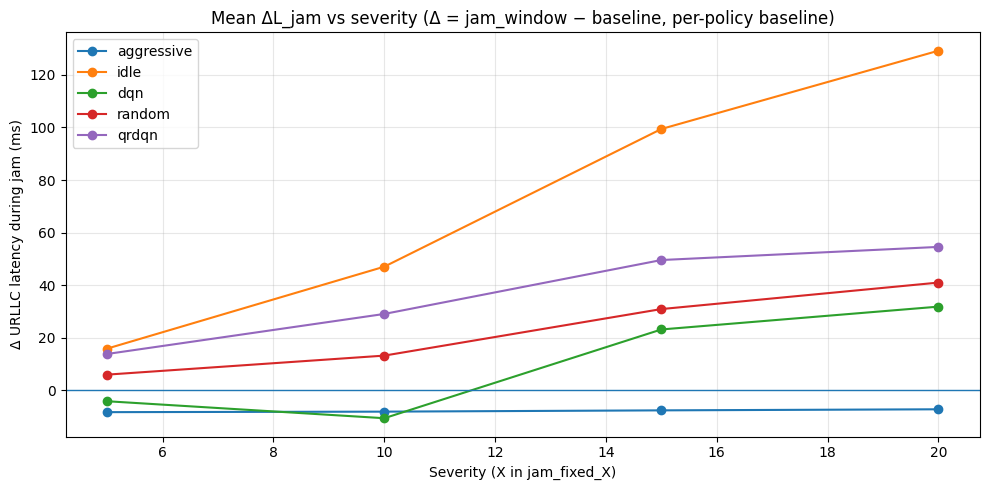

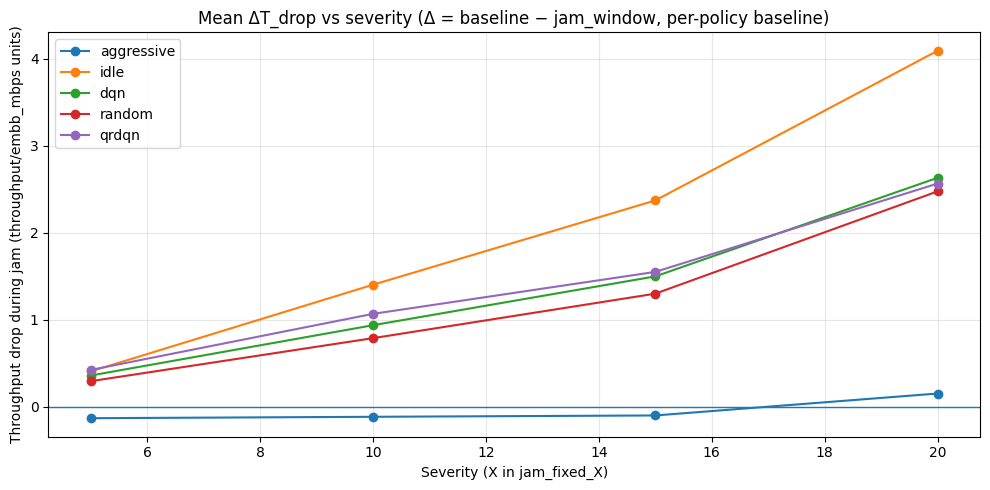

In [30]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT = Path("/home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator")

POLICIES  = ["aggressive", "idle", "dqn", "random", "qrdqn"]
SEVERITY  = [5, 10, 15, 20]  # your jam_fixed_5/10/15/20

BASELINE_FOLDER_REGEX = re.compile(r"jam_fixed_baseline_0$", re.IGNORECASE)
FIXED_FOLDER_REGEX    = re.compile(r"jam_fixed_(\d+)$", re.IGNORECASE)

EFF_TAG = "prb/effective_ratio"
LAT_TAG = "latency/urllc"          # assumed seconds -> ms
THR_TAG = "throughput/embb_mbps"  # change to throughput/embb_mbps if needed

# Jam detection
JAM_THRESH = 0.999   # jam ON if effective_ratio < this
WARMUP_STEPS = 0     # ignore first N steps if you want (e.g., 10)

# Stats
USE_MEDIAN = False   # True uses median instead of mean
LAT_IN_SECONDS = True  # set False if latency already in ms in TB

# ----------------------------
# Helpers
# ----------------------------
def event_dirs_under(run_root: Path):
    """Return all directories that directly contain events.out.tfevents.* under this run_root."""
    evs = list(run_root.rglob("events.out.tfevents.*"))
    return sorted({p.parent for p in evs})

def load_series(event_dir: Path, tag: str):
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        return None
    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)
    m = steps >= WARMUP_STEPS
    return steps[m], vals[m]

def align_on_steps(series_dict):
    """series_dict: {col: (steps, vals)} -> dataframe joined on common steps."""
    dfs = []
    for col, sv in series_dict.items():
        if sv is None:
            return None
        s, v = sv
        dfs.append(pd.DataFrame({"step": s, col: v}).set_index("step"))
    df = pd.concat(dfs, axis=1, join="inner").sort_index()
    return df if not df.empty else None

def agg_stat(x):
    return float(np.nanmedian(x) if USE_MEDIAN else np.nanmean(x))

def mean_metrics_in_window(event_dir: Path, jam_only: bool):
    """
    Returns (lat_ms, thr) averaged either during jam_only or over all samples.
    Jam is detected using effective_ratio < JAM_THRESH.
    """
    s_eff = load_series(event_dir, EFF_TAG)
    s_lat = load_series(event_dir, LAT_TAG)
    s_thr = load_series(event_dir, THR_TAG)
    df = align_on_steps({"eff": s_eff, "lat": s_lat, "thr": s_thr})
    if df is None:
        return np.nan, np.nan

    if LAT_IN_SECONDS:
        df["lat_ms"] = df["lat"] * 1000.0
    else:
        df["lat_ms"] = df["lat"]

    if jam_only:
        mask = df["eff"].values < JAM_THRESH
        if mask.sum() == 0:
            return np.nan, np.nan
        lat_ms = agg_stat(df.loc[mask, "lat_ms"].values)
        thr    = agg_stat(df.loc[mask, "thr"].values)
    else:
        lat_ms = agg_stat(df["lat_ms"].values)
        thr    = agg_stat(df["thr"].values)

    return lat_ms, thr

def collect_run_stats(run_root: Path, jam_only: bool):
    """
    A run_root can contain multiple event dirs (subruns). Compute metric per event_dir then average.
    """
    edirs = event_dirs_under(run_root)
    if not edirs:
        return np.nan, np.nan

    lats, thrs = [], []
    for ed in edirs:
        lat_ms, thr = mean_metrics_in_window(ed, jam_only=jam_only)
        if not np.isnan(lat_ms):
            lats.append(lat_ms)
        if not np.isnan(thr):
            thrs.append(thr)

    if len(lats) == 0 or len(thrs) == 0:
        return np.nan, np.nan

    return float(np.mean(lats)), float(np.mean(thrs))

# ----------------------------
# Main: per policy baseline + severity metrics
# ----------------------------
rows = []

for policy in POLICIES:
    pol_dir = TB_ROOT / policy
    if not pol_dir.exists():
        continue

    # find baseline folder inside policy dir
    baseline_folders = [p for p in pol_dir.iterdir() if p.is_dir() and BASELINE_FOLDER_REGEX.search(p.name)]
    if len(baseline_folders) == 0:
        print(f"[WARN] No baseline folder found for policy={policy}")
        continue
    baseline_root = baseline_folders[0]

    # baseline metrics (no-jam): average over all samples
    base_lat_ms, base_thr = collect_run_stats(baseline_root, jam_only=False)
    if np.isnan(base_lat_ms) or np.isnan(base_thr):
        print(f"[WARN] Baseline metrics missing for policy={policy} in {baseline_root.name}")
        continue

    print(f"policy={policy} baseline: latency={base_lat_ms:.3f} ms, thr={base_thr:.3f} ({THR_TAG})")

    # severity folders: jam_fixed_5/10/15/20
    for p in pol_dir.iterdir():
        if not p.is_dir():
            continue
        m = FIXED_FOLDER_REGEX.search(p.name)
        if not m:
            continue
        sev = int(m.group(1))
        if sev not in SEVERITY:
            continue

        jam_lat_ms, jam_thr = collect_run_stats(p, jam_only=True)
        if np.isnan(jam_lat_ms) or np.isnan(jam_thr):
            continue

        rows.append({
            "policy": policy,
            "severity": sev,
            "baseline_lat_ms": base_lat_ms,
            "baseline_thr": base_thr,
            "jam_lat_ms": jam_lat_ms,
            "jam_thr": jam_thr,
            "delta_L_jam_ms": jam_lat_ms - base_lat_ms,      # higher = worse
            "delta_T_drop": base_thr - jam_thr,              # higher = worse
            "run_folder": p.name,
        })

df = pd.DataFrame(rows)
display(df.sort_values(["policy","severity"]))

# Aggregate in case multiple runs exist per point
agg = (df.groupby(["policy","severity"], as_index=False)
         .agg(delta_L_jam_ms=("delta_L_jam_ms","mean"),
              delta_T_drop=("delta_T_drop","mean"),
              n=("run_folder","count")))
display(agg.sort_values(["policy","severity"]))

# ----------------------------
# Plots: mean ΔL_jam and mean ΔT_drop vs severity
# ----------------------------
plt.figure(figsize=(10,5))
for policy in POLICIES:
    sub = agg[agg["policy"] == policy].sort_values("severity")
    if sub.empty:
        continue
    plt.plot(sub["severity"], sub["delta_L_jam_ms"], marker="o", label=policy)
plt.axhline(0.0, linewidth=1)
plt.title("Mean ΔL_jam vs severity (Δ = jam_window − baseline, per-policy baseline)")
plt.xlabel("Severity (X in jam_fixed_X)")
plt.ylabel("Δ URLLC latency during jam (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
for policy in POLICIES:
    sub = agg[agg["policy"] == policy].sort_values("severity")
    if sub.empty:
        continue
    plt.plot(sub["severity"], sub["delta_T_drop"], marker="o", label=policy)
plt.axhline(0.0, linewidth=1)
plt.title("Mean ΔT_drop vs severity (Δ = baseline − jam_window, per-policy baseline)")
plt.xlabel("Severity (X in jam_fixed_X)")
plt.ylabel(f"Throughput drop during jam ({THR_TAG} units)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [32]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

TB_ROOT = Path("/home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator")
POLICIES = ["aggressive", "idle", "dqn", "random", "qrdqn"]
SEVERITY = [5, 10, 15, 20]

BASELINE_RE = re.compile(r"jam_fixed_baseline_0$", re.IGNORECASE)
FIXED_RE    = re.compile(r"jam_fixed_(\d+)$", re.IGNORECASE)

EFF_TAG = "prb/effective_ratio"
LAT_TAG = "latency/urllc"          # assumed seconds -> ms
THR_TAG = "throughput/urllc_mbps"  # or throughput/embb_mbps

LAT_IN_SECONDS = True

# Jam detection (hysteresis)
JAM_ON_THRESH  = 0.999
JAM_OFF_THRESH = 0.9995

# Recovery thresholds + stability
# DELTA_LAT = 0.10   # 10% band
# DELTA_THR = 0.10
DELTA_LAT = 0   # 10% band
DELTA_THR = 0
K_STABLE  = 20     # consecutive points required

WARMUP_STEPS = 0

def event_dirs_under(run_root: Path):
    evs = list(run_root.rglob("events.out.tfevents.*"))
    return sorted({p.parent for p in evs})

def load_series(event_dir: Path, tag: str):
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        return None
    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)
    m = steps >= WARMUP_STEPS
    return steps[m], vals[m]

def align_on_steps(series_dict):
    dfs = []
    for col, sv in series_dict.items():
        if sv is None:
            return None
        s, v = sv
        dfs.append(pd.DataFrame({"step": s, col: v}).set_index("step"))
    df = pd.concat(dfs, axis=1, join="inner").sort_index()
    return df if not df.empty else None

def baseline_for_policy(pol_dir: Path):
    base_folders = [p for p in pol_dir.iterdir() if p.is_dir() and BASELINE_RE.search(p.name)]
    if not base_folders:
        return None, None
    base_root = base_folders[0]

    lat_vals, thr_vals = [], []
    for ed in event_dirs_under(base_root):
        s_lat = load_series(ed, LAT_TAG)
        s_thr = load_series(ed, THR_TAG)
        if s_lat is None or s_thr is None:
            continue
        lat = np.nanmedian(s_lat[1]) if len(s_lat[1]) else np.nan
        thr = np.nanmedian(s_thr[1]) if len(s_thr[1]) else np.nan
        if not np.isnan(lat): lat_vals.append(lat)
        if not np.isnan(thr): thr_vals.append(thr)

    if not lat_vals or not thr_vals:
        return None, None

    lat0 = float(np.mean(lat_vals)) * (1000.0 if LAT_IN_SECONDS else 1.0)
    thr0 = float(np.mean(thr_vals))
    return lat0, thr0

def find_jam_cycles(df):
    """Return list of (on_step, off_step, next_on_step_or_None)."""
    eff = df["eff"].values
    steps = df.index.values

    jam_on  = eff < JAM_ON_THRESH
    jam_off = eff >= JAM_OFF_THRESH

    cycles = []
    in_jam = False
    on_step = None

    # first pass: get (on, off)
    temp = []
    for i in range(len(steps)):
        if (not in_jam) and jam_on[i]:
            in_jam = True
            on_step = int(steps[i])
        elif in_jam and jam_off[i]:
            off_step = int(steps[i])
            temp.append((on_step, off_step))
            in_jam = False
            on_step = None

    # attach next_on
    for k, (on_k, off_k) in enumerate(temp):
        next_on = temp[k+1][0] if k+1 < len(temp) else None
        cycles.append((on_k, off_k, next_on))

    return cycles

def first_recovery(df, start_step, end_cap_step, col, baseline, mode):
    """
    mode='lat': recovered if col <= baseline*(1+DELTA_LAT)
    mode='thr': recovered if col >= baseline*(1-DELTA_THR)
    Must hold for K_STABLE consecutive points.
    Only search in [start_step, end_cap_step) if cap provided.
    """
    post = df[df.index >= start_step]
    if end_cap_step is not None:
        post = post[post.index < end_cap_step]
    if post.empty:
        return None

    vals = post[col].values
    if mode == "lat":
        thr = baseline * (1 + DELTA_LAT)
        ok = vals <= thr
    else:
        thr = baseline * (1 - DELTA_THR)
        ok = vals >= thr

    for i in range(0, len(ok) - K_STABLE + 1):
        if ok[i:i+K_STABLE].all():
            return int(post.index[i])
    return None

rows = []

for policy in POLICIES:
    pol_dir = TB_ROOT / policy
    if not pol_dir.exists():
        continue

    lat0, thr0 = baseline_for_policy(pol_dir)
    if lat0 is None:
        print(f"[WARN] No baseline_0 for {policy}")
        continue

    # iterate severity folders
    for run_root in [p for p in pol_dir.iterdir() if p.is_dir()]:
        m = FIXED_RE.search(run_root.name)
        if not m:
            continue
        sev = int(m.group(1))
        if sev not in SEVERITY:
            continue

        # each run_root can contain subrun dirs with event files
        for ed in event_dirs_under(run_root):
            s_eff = load_series(ed, EFF_TAG)
            s_lat = load_series(ed, LAT_TAG)
            s_thr = load_series(ed, THR_TAG)
            df = align_on_steps({"eff": s_eff, "lat": s_lat, "thr": s_thr})
            if df is None:
                continue

            df["lat_ms"] = df["lat"] * (1000.0 if LAT_IN_SECONDS else 1.0)

            cycles = find_jam_cycles(df)
            if not cycles:
                continue

            # compute per-cycle recovery times
            for (on_s, off_s, next_on) in cycles:
                rec_lat = first_recovery(df, off_s, next_on, "lat_ms", lat0, mode="lat")
                rec_thr = first_recovery(df, off_s, next_on, "thr",    thr0, mode="thr")

                rows.append({
                    "policy": policy,
                    "severity": sev,
                    "event_dir": str(ed),
                    "jam_on_step": on_s,
                    "jam_off_step": off_s,
                    "next_jam_on_step": next_on,
                    "lat_recovered": rec_lat is not None,
                    "thr_recovered": rec_thr is not None,
                    "lat_recovery_steps": None if rec_lat is None else rec_lat - off_s,
                    "thr_recovery_steps": None if rec_thr is None else rec_thr - off_s,
                })

res = pd.DataFrame(rows)
display(res.head(20))

# Aggregate: mean recovery time + success rate (recovered before next jam)
agg = (res.groupby(["policy","severity"], as_index=False)
         .agg(lat_rec_mean=("lat_recovery_steps","mean"),
              thr_rec_mean=("thr_recovery_steps","mean"),
              lat_rec_rate=("lat_recovered","mean"),
              thr_rec_rate=("thr_recovered","mean"),
              n_cycles=("lat_recovered","count")))
display(agg.sort_values(["policy","severity"]))


,policy,severity,event_dir,jam_on_step,jam_off_step,next_jam_on_step,lat_recovered,thr_recovered,lat_recovery_steps,thr_recovery_steps
0,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,10,1250,2500.0,False,False,NaN,NaN
1,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,2500,3750,5000.0,False,False,NaN,NaN
2,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,5000,6250,7500.0,False,False,NaN,NaN
3,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,7500,8750,10010.0,False,False,NaN,NaN
4,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,10010,11250,12500.0,True,True,0.0,0.0
5,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,12500,13750,15000.0,True,True,0.0,0.0
6,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,15000,16250,17500.0,True,True,0.0,0.0
7,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,17500,18750,20010.0,True,True,0.0,0.0
8,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,20010,21250,22500.0,True,True,0.0,0.0
9,aggressive,5,/home/elahe/user/elahe/RL_work/Resilient_PRB_a...,22500,23750,25000.0,True,True,0.0,0.0


,policy,severity,lat_rec_mean,thr_rec_mean,lat_rec_rate,thr_rec_rate,n_cycles
0,aggressive,5,2.500000,0.131579,0.440,0.380,200
1,aggressive,10,2.159091,0.000000,0.440,0.380,200
2,aggressive,15,2.159091,0.000000,0.440,0.380,200
3,aggressive,20,2.159091,0.000000,0.440,0.380,200
4,dqn,5,2.921348,40.357143,0.445,0.420,200
5,dqn,10,13.295455,12.771084,0.440,0.415,200
6,dqn,15,24.157303,39.450549,0.445,0.455,200
7,dqn,20,22.553191,33.804348,0.470,0.460,200
8,idle,5,5.454545,14.750000,0.440,0.400,200
9,idle,10,68.250000,24.431818,0.400,0.440,200


In [34]:
from pathlib import Path
from collections import defaultdict
import re
import numpy as np
import pandas as pd

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event


# ============================================================
# ---------------------- CONFIG (EDIT) ------------------------
# ============================================================

ROOT = Path("../../tb_logs/res_validator")  # <-- change this

# TensorBoard tags
JAM_TAG = "prb/effective_ratio"

# Pick the metrics you want recovery-time for:
# examples you said you have:
#   "latency/urllc", "throughput/embb_mbps", "throughput/urllc"
METRIC_TAGS = [
    "latency/urllc",
    "throughput/embb_mbps",
    "throughput/urllc",
]

# Episode / timing assumptions (based on what you wrote)
SIM_STEP_SEC = 0.001              # 1 ms per simulator step (10,000 sim steps = 10 s)
DECISION_PERIOD_SIM = 10          # 1 decision step per 10 simulator steps
EPISODE_SIM_STEPS = 10_000
EPISODE_DEC_STEPS = EPISODE_SIM_STEPS // DECISION_PERIOD_SIM  # 1000

# Expected jamming pattern (your scenario)
JAM_ON_SIM = 1250
JAM_ON_DEC = JAM_ON_SIM // DECISION_PERIOD_SIM     # 125
JAM_PERIOD_SIM = 2500
JAM_PERIOD_DEC = JAM_PERIOD_SIM // DECISION_PERIOD_SIM  # 250
# Off-duration = period - on
JAM_OFF_DEC = JAM_PERIOD_DEC - JAM_ON_DEC          # 125

# Jam detection
JAM_THRESHOLD = 0.999   # tune if needed
MIN_JAM_LEN_DEC = 5     # ignore tiny blips

# Recovery definition
# "back to X" is rarely exact; use tolerance.
RECOVERY_REL_TOL = 0.01   # 1% relative tolerance
RECOVERY_ABS_TOL = 1e-9   # plus an absolute tolerance

# For recovery comparison you need to know if "higher is better" or "lower is better".
# But your definition is "return to X", so we just check |metric - X| <= tol.
# Still, if you want "recover to at least X", you can switch mode below.
RECOVERY_MODE = "within_tol"  # options: "within_tol", "at_least_X", "at_most_X"

# By default:
# - throughput: want to recover to at least X
# - latency: want to recover to at most X
TAG_DEFAULT_MODE = {
    "throughput/embb_mbps": "at_least_X",
    "throughput/urllc": "at_least_X",
    "latency/urllc": "at_most_X",
}


# ============================================================
# -------------------- TB EVENT PARSING -----------------------
# ============================================================

def iter_tb_scalars(event_file: Path, wanted_tags: set):
    """
    Yields (step, tag, value) for scalar summaries in a TF event file.
    """
    for rec in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(rec)
        if not ev.summary or not ev.summary.value:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag in wanted_tags:
                # Most scalar summaries use simple_value
                val = float(v.simple_value)
                yield step, v.tag, val


def load_tags_as_df(event_file: Path, tags: list[str]) -> pd.DataFrame:
    """
    Loads selected tags into a DataFrame indexed by global decision step.
    Columns are tag names.
    """
    wanted = set(tags)
    store = defaultdict(list)  # tag -> list of (step, value)

    for step, tag, val in iter_tb_scalars(event_file, wanted):
        store[tag].append((step, val))

    # Build per-tag series
    series = []
    for tag in tags:
        if tag not in store or len(store[tag]) == 0:
            # keep column with NaNs so downstream doesn't crash
            series.append(pd.Series(dtype=float, name=tag))
            continue
        arr = np.array(store[tag], dtype=float)
        # sort by step
        order = np.argsort(arr[:, 0])
        steps = arr[order, 0].astype(int)
        vals = arr[order, 1]
        s = pd.Series(vals, index=steps, name=tag)
        # If duplicate steps exist, keep last
        s = s[~s.index.duplicated(keep="last")]
        series.append(s)

    df = pd.concat(series, axis=1).sort_index()
    return df


# ============================================================
# ------------------- JAM DETECTION HELPERS -------------------
# ============================================================

def find_runs(boolean_array: np.ndarray):
    """
    Find contiguous True runs in a boolean array.
    Returns list of (start_idx, end_idx) inclusive.
    """
    b = boolean_array.astype(bool)
    if b.size == 0:
        return []
    # transitions
    diff = np.diff(b.astype(int))
    starts = np.where(diff == 1)[0] + 1
    ends = np.where(diff == -1)[0]

    # handle boundaries
    if b[0]:
        starts = np.r_[0, starts]
    if b[-1]:
        ends = np.r_[ends, b.size - 1]

    return list(zip(starts.astype(int), ends.astype(int)))


def tol_for_x(x: float):
    return max(RECOVERY_ABS_TOL, RECOVERY_REL_TOL * max(1.0, abs(x)))


def recovered_index(metric: np.ndarray, start_idx: int, end_idx: int, x: float, mode: str):
    """
    Search AFTER end_idx for first index where metric is considered 'recovered'
    before start_idx of next jam (the caller provides the search window).
    Returns index (absolute within episode array) or None.
    """
    if start_idx > end_idx:
        return None

    window = metric[start_idx:end_idx+1]
    if window.size == 0 or np.all(np.isnan(window)):
        return None

    if mode == "within_tol":
        t = tol_for_x(x)
        ok = np.abs(window - x) <= t
    elif mode == "at_least_X":
        t = tol_for_x(x)
        ok = window >= (x - t)
    elif mode == "at_most_X":
        t = tol_for_x(x)
        ok = window <= (x + t)
    else:
        raise ValueError(f"Unknown RECOVERY_MODE: {mode}")

    idxs = np.where(ok & ~np.isnan(window))[0]
    if idxs.size == 0:
        return None
    return start_idx + int(idxs[0])


# ============================================================
# --------------- OPTIONAL: METADATA FROM PATH ----------------
# ============================================================

def infer_metadata_from_path(p: Path) -> dict:
    """
    Best-effort parsing of policy/power/pattern if your folders encode them.
    If it can't find something, it leaves it as None.
    """
    s = str(p).lower()

    # policy guess
    policy = None
    for cand in ["aggressive", "idle", "dqn", "random", "qrdqn"]:
        if re.search(rf"\b{cand}\b", s):
            policy = cand
            break

    # power guess: "power_5", "p5", etc.
    power = None
    m = re.search(r"(power[_\- ]?)(\d+)", s)
    if not m:
        m = re.search(r"\bp(\d+)\b", s)
    if m:
        power = int(m.group(m.lastindex))

    # pattern guess
    pattern = None
    for cand in ["fixed", "increasing", "decreasing", "random"]:
        if re.search(rf"\b{cand}\b", s):
            pattern = cand
            break

    return {"policy": policy, "power": power, "pattern": pattern}


# ============================================================
# -------------------- MAIN ANALYSIS LOOP ---------------------
# ============================================================

def analyze_event_file(event_file: Path) -> pd.DataFrame:
    tags = [JAM_TAG] + METRIC_TAGS
    df = load_tags_as_df(event_file, tags)

    # If your steps are not exactly decision steps, you can still use them as "decision index".
    # We'll split episodes by EPISODE_DEC_STEPS.
    df = df.sort_index()
    if df.index.size == 0:
        return pd.DataFrame()

    meta = infer_metadata_from_path(event_file)
    rows = []

    # group by episode id derived from global step
    # episode_id = global_step // EPISODE_DEC_STEPS
    # within_episode_step = global_step % EPISODE_DEC_STEPS
    df = df.copy()
    df["episode_id"] = (df.index.values // EPISODE_DEC_STEPS).astype(int)
    df["t_dec"] = (df.index.values % EPISODE_DEC_STEPS).astype(int)

    for ep_id, g in df.groupby("episode_id", sort=True):
        g = g.sort_values("t_dec")
        # build episode arrays for jam tag and each metric
        # We want a dense array length EPISODE_DEC_STEPS (0..999)
        ep = pd.DataFrame(index=np.arange(EPISODE_DEC_STEPS))
        ep[JAM_TAG] = np.nan
        for t in METRIC_TAGS:
            ep[t] = np.nan

        # fill known points
        ep.loc[g["t_dec"].values, JAM_TAG] = g[JAM_TAG].values
        for t in METRIC_TAGS:
            ep.loc[g["t_dec"].values, t] = g[t].values

        # If logging is sparse, you can forward-fill; often metrics are logged every decision step.
        ep = ep.ffill()

        jam_ratio = ep[JAM_TAG].to_numpy(dtype=float)
        jam_bool = np.isfinite(jam_ratio) & (jam_ratio < JAM_THRESHOLD)

        jam_runs = find_runs(jam_bool)

        # Filter tiny runs
        jam_runs = [(s, e) for (s, e) in jam_runs if (e - s + 1) >= MIN_JAM_LEN_DEC]

        # Optional sanity: if you want to snap to expected lengths, uncomment:
        # jam_runs = [(s, min(e, s + JAM_ON_DEC - 1)) for (s, e) in jam_runs]

        for j_i, (s, e) in enumerate(jam_runs):
            next_s = jam_runs[j_i + 1][0] if (j_i + 1) < len(jam_runs) else EPISODE_DEC_STEPS
            # Recovery search window: after jam ends until before next jam starts
            rec_start = e + 1
            rec_end = next_s - 1

            # compute X,Y,recovery per metric
            for metric_tag in METRIC_TAGS:
                metric = ep[metric_tag].to_numpy(dtype=float)

                X = metric[s] if s < len(metric) else np.nan
                Y = metric[e] if e < len(metric) else np.nan

                # Determine mode per tag (fallback to global)
                mode = TAG_DEFAULT_MODE.get(metric_tag, RECOVERY_MODE)

                rec_idx = None
                recovered = False
                recovery_dec_steps = np.nan
                end_value_before_nextjam = np.nan

                if rec_start <= rec_end and np.isfinite(X):
                    rec_idx = recovered_index(metric, rec_start, rec_end, float(X), mode)
                    if rec_idx is not None:
                        recovered = True
                        recovery_dec_steps = int(rec_idx - rec_start)  # from first step AFTER jam end
                    else:
                        recovered = False
                        end_value_before_nextjam = metric[rec_end] if rec_end < len(metric) else np.nan
                else:
                    # no room to recover (jam at end), or X is nan
                    recovered = False
                    if rec_end >= 0 and rec_end < len(metric):
                        end_value_before_nextjam = metric[rec_end]

                # Convert recovery time to sim steps and seconds
                if recovered and np.isfinite(recovery_dec_steps):
                    recovery_sim_steps = int(recovery_dec_steps * DECISION_PERIOD_SIM)
                    recovery_seconds = recovery_sim_steps * SIM_STEP_SEC
                else:
                    recovery_sim_steps = np.nan
                    recovery_seconds = np.nan

                rows.append({
                    "file": str(event_file),
                    "policy": meta["policy"],
                    "power": meta["power"],
                    "pattern": meta["pattern"],

                    "episode": int(ep_id),
                    "jam_index_in_episode": int(j_i),

                    "jam_start_dec": int(s),
                    "jam_end_dec": int(e),
                    "jam_duration_dec": int(e - s + 1),

                    "jam_start_sim": int(s * DECISION_PERIOD_SIM),
                    "jam_end_sim": int((e + 1) * DECISION_PERIOD_SIM - 1),
                    "jam_duration_sim": int((e - s + 1) * DECISION_PERIOD_SIM),

                    "metric": metric_tag,
                    "X_at_jam_start": float(X) if np.isfinite(X) else np.nan,
                    "Y_at_jam_end": float(Y) if np.isfinite(Y) else np.nan,

                    "recovered": bool(recovered),
                    "recovery_dec_steps": recovery_dec_steps,
                    "recovery_sim_steps": recovery_sim_steps,
                    "recovery_seconds": recovery_seconds,

                    "end_value_before_nextjam": float(end_value_before_nextjam) if np.isfinite(end_value_before_nextjam) else np.nan,
                    "recovery_mode": mode,
                })

    return pd.DataFrame(rows)


def find_event_files(root: Path):
    # Typical TensorBoard event filenames contain "tfevents"
    return sorted([p for p in root.rglob("*") if p.is_file() and "tfevents" in p.name])


# ============================================================
# ------------------------- RUN IT ----------------------------
# ============================================================

event_files = find_event_files(ROOT)
print(f"Found {len(event_files)} event files")

all_res = []
for f in event_files:
    try:
        df_res = analyze_event_file(f)
        if len(df_res) > 0:
            all_res.append(df_res)
    except Exception as e:
        print(f"[WARN] Failed on {f}: {e}")

results = pd.concat(all_res, ignore_index=True) if all_res else pd.DataFrame()
print("Results shape:", results.shape)

# Save
out_csv = ROOT / "recovery_time_results.csv"
results.to_csv(out_csv, index=False)
print("Saved:", out_csv)

# Quick summaries (mean recovery per policy/power/pattern/metric)
if not results.empty:
    summary = (results
               .groupby(["policy", "power", "pattern", "metric"], dropna=False)
               .agg(
                    jams=("recovered", "size"),
                    recovered_rate=("recovered", "mean"),
                    mean_recovery_s=("recovery_seconds", "mean"),
                    median_recovery_s=("recovery_seconds", "median"),
               )
               .reset_index())
    print("\nSummary (head):")
    print(summary.head(20))

    summary_csv = ROOT / "recovery_time_summary.csv"
    summary.to_csv(summary_csv, index=False)
    print("Saved:", summary_csv)


Found 46 event files
Results shape: (48000, 21)
Saved: ../../tb_logs/res_validator/recovery_time_results.csv

Summary (head):
        policy  power pattern                metric  jams  recovered_rate  \
0   aggressive    NaN     NaN         latency/urllc  3200        0.365000   
1   aggressive    NaN     NaN  throughput/embb_mbps  3200        0.499375   
2   aggressive    NaN     NaN      throughput/urllc  3200        0.000000   
3          dqn    NaN     NaN         latency/urllc  3200        0.395625   
4          dqn    NaN     NaN  throughput/embb_mbps  3200        0.498125   
5          dqn    NaN     NaN      throughput/urllc  3200        0.000000   
6         idle    NaN     NaN         latency/urllc  3200        0.268437   
7         idle    NaN     NaN  throughput/embb_mbps  3200        0.498750   
8         idle    NaN     NaN      throughput/urllc  3200        0.000000   
9        qrdqn    NaN     NaN         latency/urllc  3200        0.382500   
10       qrdqn    NaN     N